In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("MandiMitra India Environment Ready!")

MandiMitra India Environment Ready!


In [2]:
# Load dataset
df = pd.read_csv("All_India_Mandi_2026.csv")

# Convert date column
df['Arrival_Date'] = pd.to_datetime(df['Arrival_Date'])

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (582310, 11)

First 5 Records:


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
0,Maharashtra,Nagpur,Nagpur APMC,Tomato,Other,Local,2026-01-01,4000.0,5000.0,4725.0,78
1,Gujarat,Anand,"Anand (Veg,Yard,Anand) APMC",Cabbage,Cabbage,Grade B,2026-01-01,500.0,1000.0,750.0,154
2,Tamil Nadu,Kancheepuram,Sunguvarchatram (Uzhavar Sandhai ) APMC,Ashgourd,Gouard,Local,2026-01-01,2500.0,3000.0,2750.0,83
3,Tamil Nadu,Namakkal,Mohanur (Uzhavar Sandhai ) APMC,Pumpkin,Pumpkin,Local,2026-01-01,1400.0,2000.0,1700.0,84
4,Tamil Nadu,Pudukkottai,Gandarvakottai (Uzhavar Sandhai ) APMC,Tapioca,Tapioca,Local,2026-01-01,1500.0,2000.0,1750.0,100



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582310 entries, 0 to 582309
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   State           582310 non-null  object        
 1   District        582310 non-null  object        
 2   Market          582310 non-null  object        
 3   Commodity       582310 non-null  object        
 4   Variety         582310 non-null  object        
 5   Grade           582310 non-null  object        
 6   Arrival_Date    582310 non-null  datetime64[ns]
 7   Min_Price       582303 non-null  float64       
 8   Max_Price       582310 non-null  float64       
 9   Modal_Price     582310 non-null  float64       
 10  Commodity_Code  582310 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 48.9+ MB


In [4]:
print("Total Records:", len(df))

print("Total States:", df['State'].nunique())

print("Total Districts:", df['District'].nunique())

print("Total Markets:", df['Market'].nunique())

print("Total Commodities:", df['Commodity'].nunique())

print("\nDate Range:")
print("Start:", df['Arrival_Date'].min())
print("End:", df['Arrival_Date'].max())

Total Records: 582310
Total States: 30
Total Districts: 542
Total Markets: 3055
Total Commodities: 316

Date Range:
Start: 2026-01-01 00:00:00
End: 2026-04-21 00:00:00


In [5]:
missing_data = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_data)

,Missing_Count,Missing_Percentage
State,0,0.0
District,0,0.0
Market,0,0.0
Commodity,0,0.0
Variety,0,0.0
Grade,0,0.0
Arrival_Date,0,0.0
Min_Price,7,0.0
Max_Price,0,0.0
Modal_Price,0,0.0


In [6]:
missing_rows = df[df['Min_Price'].isnull()]

display(missing_rows)

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
35531,Tamil Nadu,Cuddalore,Shrimushnam APMC,Bajra (Pearl Millet/Cumbu),Other,Local,2026-01-07,NaN,2159.0,1079.5,28
131317,Tamil Nadu,Thanjavur,Kumbakonam (Uzhavar Sandhai ) APMC,Bhindi (Ladies Finger),Bhindi,Local,2026-01-28,NaN,6000.0,3000.0,85
257424,Tamil Nadu,Ariyalur,Andimadom APMC,Bajra (Pearl Millet/Cumbu),Other,Local,2026-02-11,NaN,3825.0,1912.5,28
377880,Tamil Nadu,Ariyalur,Andimadom APMC,Paddy (Common),B P T,Local,2026-01-08,NaN,1733.0,866.5,2
395432,Tamil Nadu,Thiruvannamalai,Tamarainagar (Uzhavar Sandhai ) APMC,Amla (Nelli Kai),Amla,Local,2026-02-21,NaN,8200.0,4100.0,355
402400,Tamil Nadu,Ariyalur,Andimadom APMC,Bajra (Pearl Millet/Cumbu),Other,Local,2026-01-08,NaN,3400.0,1700.0,28
413264,Tamil Nadu,Salem,Hasthampatti (Uzhavar Sandhai ) APMC,Ginger (Green),Green Ginger,Local,2026-01-20,NaN,8000.0,4000.0,103


In [7]:
print("Total Duplicate Rows:", df.duplicated().sum())

# Check duplicates based on important columns
duplicate_columns = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade',
    'Arrival_Date'
]

print(
    "Potential Duplicate Market Records:",
    df.duplicated(subset=duplicate_columns).sum()
)

Total Duplicate Rows: 0
Potential Duplicate Market Records: 0


In [8]:
price_columns = [
    'Min_Price',
    'Max_Price',
    'Modal_Price'
]

print("PRICE DATA TYPES")

print(df[price_columns].dtypes)

print("\nPRICE STATISTICS")

display(df[price_columns].describe())

PRICE DATA TYPES
Min_Price      float64
Max_Price      float64
Modal_Price    float64
dtype: object

PRICE STATISTICS


,Min_Price,Max_Price,Modal_Price
count,582303.000000,582310.000000,582310.000000
mean,4101.705658,4839.607883,4493.106968
std,6141.776476,7316.158885,6611.853174
min,0.030000,0.500000,0.500000
25%,2000.000000,2372.000000,2200.000000
50%,3000.000000,3600.000000,3500.000000
75%,5000.000000,5580.000000,5251.000000
max,980083.000000,980083.000000,980083.000000


In [9]:
invalid_prices = df[
    (df['Min_Price'] < 0) |
    (df['Max_Price'] < 0) |
    (df['Modal_Price'] < 0) |
    (df['Min_Price'] > df['Max_Price']) |
    (df['Modal_Price'] < df['Min_Price']) |
    (df['Modal_Price'] > df['Max_Price'])
]

print("Invalid Price Records:", len(invalid_prices))

display(invalid_prices.head(20))

Invalid Price Records: 0


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code


In [10]:
for col in price_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\n{col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outliers:", len(outliers))


Min_Price
Lower Limit: -2500.0
Upper Limit: 9500.0
Outliers: 28824

Max_Price
Lower Limit: -2440.0
Upper Limit: 10392.0
Outliers: 33075

Modal_Price
Lower Limit: -2376.5
Upper Limit: 9827.5
Outliers: 32403


In [11]:
print("Earliest Date:", df['Arrival_Date'].min())

print("Latest Date:", df['Arrival_Date'].max())

print("Unique Trading Dates:", df['Arrival_Date'].nunique())

print("Missing Dates:",
      df['Arrival_Date'].isnull().sum())

Earliest Date: 2026-01-01 00:00:00
Latest Date: 2026-04-21 00:00:00
Unique Trading Dates: 106
Missing Dates: 0


In [12]:
df['Year'] = df['Arrival_Date'].dt.year

df['Month'] = df['Arrival_Date'].dt.month

df['Month_Name'] = df['Arrival_Date'].dt.month_name()

df['Day'] = df['Arrival_Date'].dt.day

df['Day_Name'] = df['Arrival_Date'].dt.day_name()

df['Quarter'] = df['Arrival_Date'].dt.quarter

display(df.head())

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Year,Month,Month_Name,Day,Day_Name,Quarter
0,Maharashtra,Nagpur,Nagpur APMC,Tomato,Other,Local,2026-01-01,4000.0,5000.0,4725.0,78,2026,1,January,1,Thursday,1
1,Gujarat,Anand,"Anand (Veg,Yard,Anand) APMC",Cabbage,Cabbage,Grade B,2026-01-01,500.0,1000.0,750.0,154,2026,1,January,1,Thursday,1
2,Tamil Nadu,Kancheepuram,Sunguvarchatram (Uzhavar Sandhai ) APMC,Ashgourd,Gouard,Local,2026-01-01,2500.0,3000.0,2750.0,83,2026,1,January,1,Thursday,1
3,Tamil Nadu,Namakkal,Mohanur (Uzhavar Sandhai ) APMC,Pumpkin,Pumpkin,Local,2026-01-01,1400.0,2000.0,1700.0,84,2026,1,January,1,Thursday,1
4,Tamil Nadu,Pudukkottai,Gandarvakottai (Uzhavar Sandhai ) APMC,Tapioca,Tapioca,Local,2026-01-01,1500.0,2000.0,1750.0,100,2026,1,January,1,Thursday,1


In [13]:
# Create EDA dataset
eda_df = df.copy()

# Remove records with missing price values for price analysis
eda_df = eda_df.dropna(
    subset=['Min_Price', 'Max_Price', 'Modal_Price']
)

print("EDA Dataset Shape:", eda_df.shape)

EDA Dataset Shape: (582303, 17)


In [14]:
# Price difference
eda_df['Price_Range'] = (
    eda_df['Max_Price'] - eda_df['Min_Price']
)

# Price spread percentage
eda_df['Price_Spread'] = (
    eda_df['Price_Range'] /
    eda_df['Modal_Price'].replace(0, np.nan)
) * 100

# Price category based on modal price
eda_df['Price_Category'] = pd.cut(
    eda_df['Modal_Price'],
    bins=[-np.inf, 2000, 5000, 10000, np.inf],
    labels=['Low', 'Medium', 'High', 'Very High']
)

display(eda_df.head())

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Year,Month,Month_Name,Day,Day_Name,Quarter,Price_Range,Price_Spread,Price_Category
0,Maharashtra,Nagpur,Nagpur APMC,Tomato,Other,Local,2026-01-01,4000.0,5000.0,4725.0,78,2026,1,January,1,Thursday,1,1000.0,21.164021,Medium
1,Gujarat,Anand,"Anand (Veg,Yard,Anand) APMC",Cabbage,Cabbage,Grade B,2026-01-01,500.0,1000.0,750.0,154,2026,1,January,1,Thursday,1,500.0,66.666667,Low
2,Tamil Nadu,Kancheepuram,Sunguvarchatram (Uzhavar Sandhai ) APMC,Ashgourd,Gouard,Local,2026-01-01,2500.0,3000.0,2750.0,83,2026,1,January,1,Thursday,1,500.0,18.181818,Medium
3,Tamil Nadu,Namakkal,Mohanur (Uzhavar Sandhai ) APMC,Pumpkin,Pumpkin,Local,2026-01-01,1400.0,2000.0,1700.0,84,2026,1,January,1,Thursday,1,600.0,35.294118,Low
4,Tamil Nadu,Pudukkottai,Gandarvakottai (Uzhavar Sandhai ) APMC,Tapioca,Tapioca,Local,2026-01-01,1500.0,2000.0,1750.0,100,2026,1,January,1,Thursday,1,500.0,28.571429,Low


In [15]:
state_analysis = (
    eda_df.groupby('State')
    .agg(
        Average_Price=('Modal_Price', 'mean'),
        Maximum_Price=('Modal_Price', 'max'),
        Minimum_Price=('Modal_Price', 'min'),
        Total_Records=('Modal_Price', 'count'),
        Total_Commodities=('Commodity', 'nunique')
    )
    .round(2)
    .sort_values(
        by='Average_Price',
        ascending=False
    )
)

display(state_analysis.head(15))

,Average_Price,Maximum_Price,Minimum_Price,Total_Records,Total_Commodities
State,,,,,
Goa,13402.58,44900.0,8.5,381,20
Manipur,8750.61,24000.0,1750.0,866,20
Meghalaya,8393.66,52500.0,1250.0,339,28
NCT of Delhi,7467.11,220000.0,11.0,3271,103
Karnataka,7215.38,98320.0,9.0,13615,125
Andhra Pradesh,5824.55,23000.0,300.0,1494,40
Kerala,5500.90,980083.0,0.5,48670,109
Andaman and Nicobar,5337.46,26000.0,1500.0,283,33
Tripura,5032.90,50000.0,200.0,5648,48


In [16]:
state_analysis = (
    eda_df.groupby('State')
    .agg(
        Average_Price=('Modal_Price', 'mean'),
        Maximum_Price=('Modal_Price', 'max'),
        Minimum_Price=('Modal_Price', 'min'),
        Total_Records=('Modal_Price', 'count'),
        Total_Commodities=('Commodity', 'nunique')
    )
    .round(2)
    .sort_values(
        by='Average_Price',
        ascending=False
    )
)

display(state_analysis.head(15))

,Average_Price,Maximum_Price,Minimum_Price,Total_Records,Total_Commodities
State,,,,,
Goa,13402.58,44900.0,8.5,381,20
Manipur,8750.61,24000.0,1750.0,866,20
Meghalaya,8393.66,52500.0,1250.0,339,28
NCT of Delhi,7467.11,220000.0,11.0,3271,103
Karnataka,7215.38,98320.0,9.0,13615,125
Andhra Pradesh,5824.55,23000.0,300.0,1494,40
Kerala,5500.90,980083.0,0.5,48670,109
Andaman and Nicobar,5337.46,26000.0,1500.0,283,33
Tripura,5032.90,50000.0,200.0,5648,48


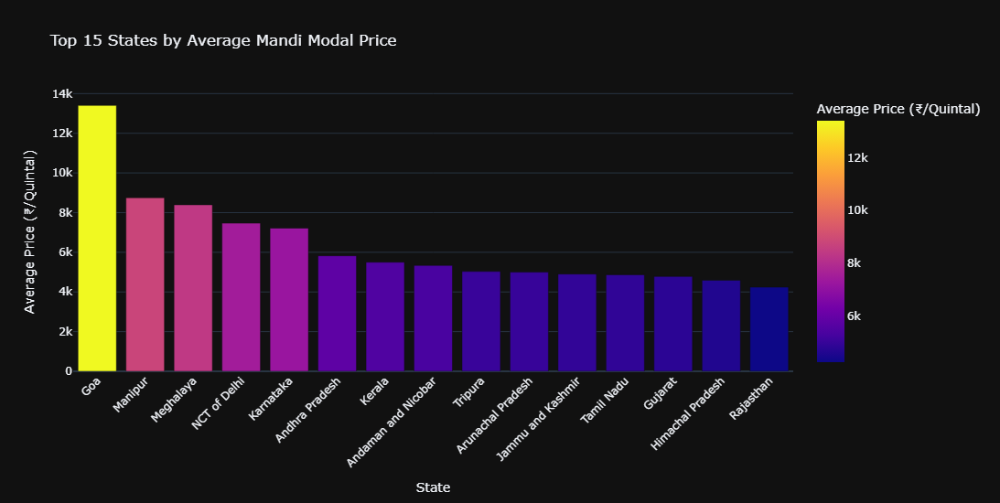

In [17]:
top_states = state_analysis.head(15).reset_index()

fig = px.bar(
    top_states,
    x='State',
    y='Average_Price',
    color='Average_Price',
    title='Top 15 States by Average Mandi Modal Price',
    labels={
        'Average_Price': 'Average Price (₹/Quintal)',
        'State': 'State'
    },
    template='plotly_dark'
)

fig.update_layout(
    xaxis_tickangle=-45,
    height=550
)

fig.show()

In [18]:
commodity_analysis = (
    eda_df.groupby('Commodity')
    .agg(
        Average_Price=('Modal_Price', 'mean'),
        Maximum_Price=('Modal_Price', 'max'),
        Minimum_Price=('Modal_Price', 'min'),
        Total_Records=('Modal_Price', 'count'),
        States_Available=('State', 'nunique')
    )
    .round(2)
    .sort_values(
        by='Average_Price',
        ascending=False
    )
)

display(commodity_analysis.head(20))

,Average_Price,Maximum_Price,Minimum_Price,Total_Records,States_Available
Commodity,,,,,
Cardamom,255484.62,345000.0,224300.0,13,2
Cardamoms,217018.75,280000.0,160000.0,32,2
tulip,150000.00,170000.0,120000.0,8,1
Tulip,132000.00,170000.0,120000.0,5,1
poppy seeds,119943.58,147700.0,60000.0,62,2
Chakotha,106166.67,310000.0,4000.0,3,1
Raibel,105111.11,220000.0,25000.0,18,1
Almond (Badam),101600.00,102500.0,98000.0,15,1
Jasmine,93119.30,795000.0,17000.0,285,3


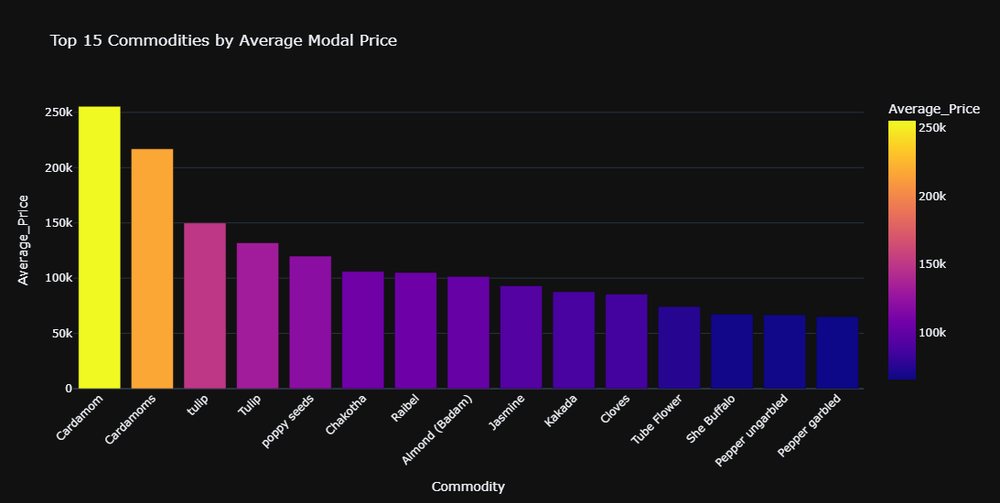

In [19]:
top_commodities = (
    commodity_analysis.head(15)
    .reset_index()
)

fig = px.bar(
    top_commodities,
    x='Commodity',
    y='Average_Price',
    color='Average_Price',
    title='Top 15 Commodities by Average Modal Price',
    template='plotly_dark'
)

fig.update_layout(
    xaxis_tickangle=-45,
    height=550
)

fig.show()

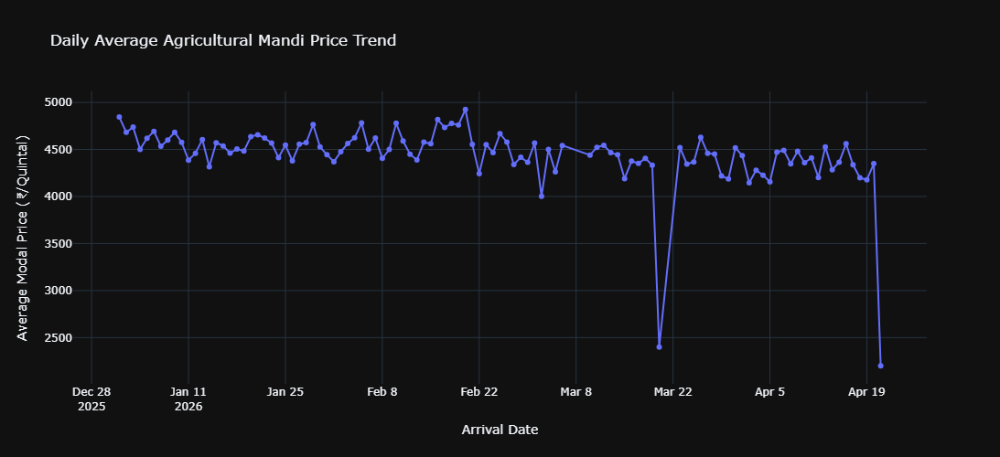

In [20]:
daily_trend = (
    eda_df.groupby('Arrival_Date')
    ['Modal_Price']
    .mean()
    .reset_index()
)

fig = px.line(
    daily_trend,
    x='Arrival_Date',
    y='Modal_Price',
    title='Daily Average Agricultural Mandi Price Trend',
    markers=True,
    template='plotly_dark'
)

fig.update_layout(
    height=500,
    xaxis_title='Arrival Date',
    yaxis_title='Average Modal Price (₹/Quintal)'
)

fig.show()

In [21]:
selected_commodity = 'Wheat'

wheat_data = eda_df[
    eda_df['Commodity'].str.lower()
    == selected_commodity.lower()
]

wheat_state = (
    wheat_data.groupby('State')
    ['Modal_Price']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

display(wheat_state.head(20))

,State,Modal_Price
0,Karnataka,2871.829114
1,Punjab,2844.949438
2,West Bengal,2730.517799
3,NCT of Delhi,2616.022727
4,Himachal Pradesh,2585.000000
5,Haryana,2584.366516
6,Bihar,2576.000000
7,Maharashtra,2542.200112
8,Uttarakhand,2509.413043
9,Gujarat,2474.145903


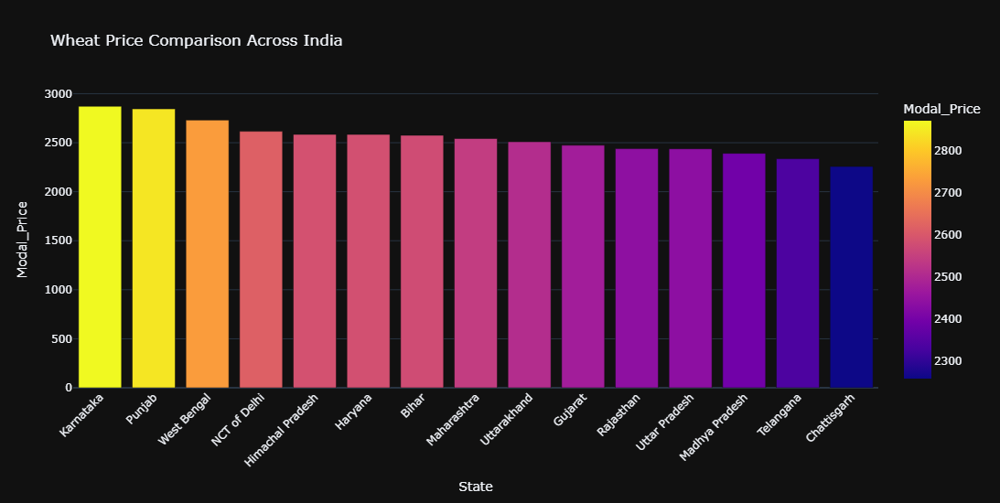

In [22]:
fig = px.bar(
    wheat_state.head(20),
    x='State',
    y='Modal_Price',
    color='Modal_Price',
    title=f'{selected_commodity} Price Comparison Across India',
    template='plotly_dark'
)

fig.update_layout(
    xaxis_tickangle=-45,
    height=550
)

fig.show()

In [23]:
mandi_analysis = (
    eda_df.groupby(
        ['State', 'District', 'Market', 'Commodity']
    )
    .agg(
        Average_Price=('Modal_Price', 'mean'),
        Maximum_Price=('Modal_Price', 'max'),
        Minimum_Price=('Modal_Price', 'min'),
        Records=('Modal_Price', 'count')
    )
    .round(2)
    .reset_index()
)

# Highest average price
expensive_mandis = mandi_analysis.sort_values(
    by='Average_Price',
    ascending=False
)

print("TOP 15 EXPENSIVE MANDI-COMMODITY COMBINATIONS")

display(expensive_mandis.head(15))

print("TOP 15 CHEAPEST MANDI-COMMODITY COMBINATIONS")

display(
    mandi_analysis.sort_values(
        by='Average_Price'
    ).head(15)
)

TOP 15 EXPENSIVE MANDI-COMMODITY COMBINATIONS


,State,District,Market,Commodity,Average_Price,Maximum_Price,Minimum_Price,Records
18968,Punjab,Patiala,Samana APMC,Guava,410000.00,410000.0,410000.0,1
17564,Punjab,Ferozpur,Zira APMC,Lime,330000.00,330000.0,330000.0,1
7844,Kerala,Idukki,Kattappana APMC,Cardamom,264000.00,345000.0,235000.0,5
14515,Maharashtra,Mumbai,Mumbai APMC,Cardamom,260000.00,260000.0,260000.0,5
7980,Kerala,Idukki,Thodupuzha APMC,Cardamoms,253550.00,260700.0,246400.0,2
7979,Kerala,Idukki,Thodupuzha APMC,Cardamom,233766.67,247800.0,224300.0,3
7845,Kerala,Idukki,Kattappana APMC,Cardamoms,225333.33,280000.0,160000.0,15
7892,Kerala,Idukki,Munnar APMC,Cashewnuts,223333.33,320000.0,120000.0,3
14516,Maharashtra,Mumbai,Mumbai APMC,Cardamoms,203833.33,260000.0,187500.0,15
27944,Tamil Nadu,Ramanathapuram,Ramanathapuram (Uzhavar Sandhai ) APMC,Jasmine,187857.14,795000.0,32500.0,28


TOP 15 CHEAPEST MANDI-COMMODITY COMBINATIONS


,State,District,Market,Commodity,Average_Price,Maximum_Price,Minimum_Price,Records
290,Assam,Hojai,Gandhimaidan APMC,Lemon,2.50,2.50,2.50,1
349,Assam,Kamrup,Pamohi (Garchuk) APMC,Banana - Green,2.52,2.75,2.25,6
15220,Maharashtra,Pune,Pune (Khadiki) APMC,Mint (Pudina),2.77,3.00,2.00,13
19290,Punjab,Tarntaran,Patti APMC,Leafy Vegetable,2.98,3.60,2.30,4
335,Assam,Kamrup,P.O. Uparhali Guwahati APMC,Lemon,3.00,3.00,3.00,1
409,Assam,Morigaon,Moirabari APMC,Lemon,3.00,3.00,3.00,1
317,Assam,Kamrup,P.O. Uparhali Guwahati APMC,Betelnuts,3.16,3.50,3.00,8
19281,Punjab,Tarntaran,Patti APMC,Cauliflower,3.18,5.00,2.00,5
15377,Maharashtra,Pune,Pune APMC,Mint (Pudina),3.18,4.00,3.00,17
15219,Maharashtra,Pune,Pune (Khadiki) APMC,Methi (Leaves),3.25,4.00,3.00,4


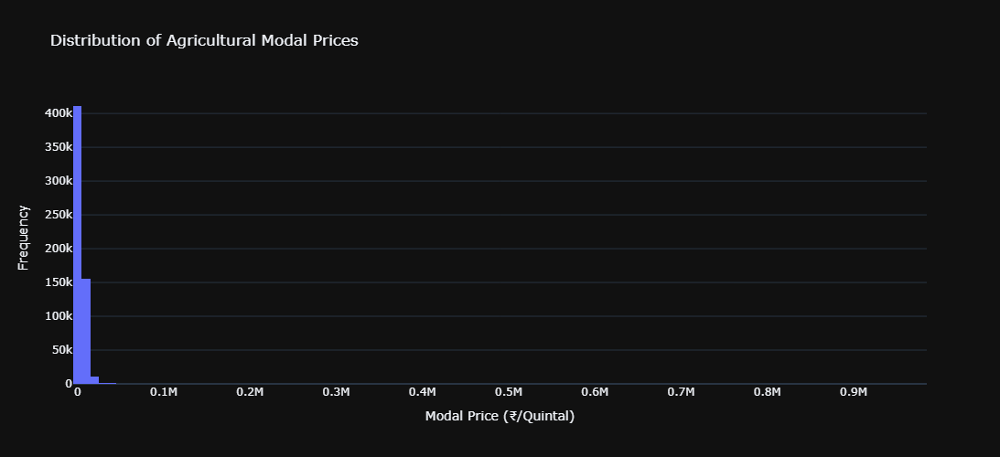

In [24]:
fig = px.histogram(
    eda_df,
    x='Modal_Price',
    nbins=100,
    title='Distribution of Agricultural Modal Prices',
    template='plotly_dark'
)

fig.update_layout(
    height=500,
    xaxis_title='Modal Price (₹/Quintal)',
    yaxis_title='Frequency'
)

fig.show()

In [25]:
eda_df.to_csv(
    'MandiMitra_India_EDA.csv',
    index=False
)

print("EDA Dataset Saved Successfully!")

EDA Dataset Saved Successfully!


In [26]:
# Create a copy
ml_df = eda_df.copy()

# Ensure date format
ml_df['Arrival_Date'] = pd.to_datetime(
    ml_df['Arrival_Date']
)

# Sort records
ml_df = ml_df.sort_values('Arrival_Date')

print("Dataset Shape:", ml_df.shape)

display(ml_df.head())

Dataset Shape: (582303, 20)


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Year,Month,Month_Name,Day,Day_Name,Quarter,Price_Range,Price_Spread,Price_Category
0,Maharashtra,Nagpur,Nagpur APMC,Tomato,Other,Local,2026-01-01,4000.0,5000.0,4725.0,78,2026,1,January,1,Thursday,1,1000.0,21.164021,Medium
250724,Tamil Nadu,Kallakuruchi,Sankarapuram (Uzhavar Sandhai ) APMC,Custard Apple (Sharifa),Custard Apple (Sharifa),Local,2026-01-01,6000.0,6000.0,6000.0,352,2026,1,January,1,Thursday,1,0.0,0.000000,High
297502,Tamil Nadu,Nagapattinam,Mayiladuthurai (Uzhavar Sandhai ) APMC,Bitter gourd,Bitter Gourd,Local,2026-01-01,5500.0,6000.0,5750.0,81,2026,1,January,1,Thursday,1,500.0,8.695652,High
471032,Tamil Nadu,Ranipet,Arcot (Uzhavar Sandhai ) APMC,Green Peas,Green Peas,Local,2026-01-01,6000.0,6000.0,6000.0,50,2026,1,January,1,Thursday,1,0.0,0.000000,High
471031,Rajasthan,Udaipur,Udaipur (F&V) APMC,Mousambi (Sweet Lime),Other,Medium,2026-01-01,2000.0,3000.0,2500.0,77,2026,1,January,1,Thursday,1,1000.0,40.000000,Medium


In [27]:
categorical_columns = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

for col in categorical_columns:
    ml_df[col] = (
        ml_df[col]
        .fillna('Unknown')
        .astype(str)
        .str.strip()
    )

print("Categorical Missing Values:")

display(ml_df[categorical_columns].isnull().sum())

Categorical Missing Values:


State        0
District     0
Market       0
Commodity    0
Variety      0
Grade        0
dtype: int64

In [28]:
group_columns = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

ml_df['Market_ID'] = (
    ml_df[group_columns]
    .astype(str)
    .agg('_'.join, axis=1)
)

print("Unique Market-Combinations:",
      ml_df['Market_ID'].nunique())

Unique Market-Combinations: 54001


In [29]:
aggregation = {
    'Min_Price': 'mean',
    'Max_Price': 'mean',
    'Modal_Price': 'mean',
    'Commodity_Code': 'first'
}

ml_df = (
    ml_df.groupby(
        group_columns + ['Arrival_Date'],
        as_index=False
    )
    .agg(aggregation)
)

print("Dataset after daily aggregation:", ml_df.shape)

Dataset after daily aggregation: (582303, 11)


In [30]:
ml_df['Year'] = ml_df['Arrival_Date'].dt.year

ml_df['Month'] = ml_df['Arrival_Date'].dt.month

ml_df['Day'] = ml_df['Arrival_Date'].dt.day

ml_df['Day_of_Week'] = (
    ml_df['Arrival_Date'].dt.dayofweek
)

ml_df['Week_of_Year'] = (
    ml_df['Arrival_Date'].dt.isocalendar().week.astype(int)
)

ml_df['Quarter'] = (
    ml_df['Arrival_Date'].dt.quarter
)

ml_df['Is_Weekend'] = (
    ml_df['Day_of_Week'] >= 5
).astype(int)

display(ml_df.head())

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Year,Month,Day,Day_of_Week,Week_of_Year,Quarter,Is_Weekend
0,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,Other,FAQ,2026-03-11,2000.0,5000.0,2500.0,83,2026,3,11,2,11,1,0
1,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,Other,FAQ,2026-03-14,2500.0,5000.0,3000.0,83,2026,3,14,5,11,1,1
2,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,Other,FAQ,2026-03-23,2000.0,4000.0,3000.0,83,2026,3,23,0,13,1,0
3,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,Other,FAQ,2026-03-25,2000.0,4000.0,3000.0,83,2026,3,25,2,13,1,0
4,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,Other,FAQ,2026-03-31,2000.0,4000.0,3000.0,83,2026,3,31,1,14,1,0


In [31]:
ml_df = ml_df.sort_values(
    group_columns + ['Arrival_Date']
)

for lag in [1, 2, 3, 7]:
    
    ml_df[f'Lag_{lag}'] = (
        ml_df.groupby(group_columns)['Modal_Price']
        .shift(lag)
    )

display(
    ml_df[
        group_columns[:4] +
        ['Arrival_Date', 'Modal_Price',
         'Lag_1', 'Lag_2', 'Lag_3', 'Lag_7']
    ].head(20)
)

,State,District,Market,Commodity,Arrival_Date,Modal_Price,Lag_1,Lag_2,Lag_3,Lag_7
0,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-11,2500.0,NaN,NaN,NaN,NaN
1,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-14,3000.0,2500.0,NaN,NaN,NaN
2,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-23,3000.0,3000.0,2500.0,NaN,NaN
3,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-25,3000.0,3000.0,3000.0,2500.0,NaN
4,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-31,3000.0,3000.0,3000.0,3000.0,NaN
5,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-01,3000.0,3000.0,3000.0,3000.0,NaN
6,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-06,3000.0,3000.0,3000.0,3000.0,NaN
7,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-15,3000.0,3000.0,3000.0,3000.0,2500.0
8,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-20,3000.0,3000.0,3000.0,3000.0,3000.0
9,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Banana,2026-03-18,4500.0,NaN,NaN,NaN,NaN


In [32]:
for window in [3, 7, 14]:

    ml_df[f'Rolling_Mean_{window}'] = (
        ml_df.groupby(group_columns)['Modal_Price']
        .transform(
            lambda x: x.shift(1).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

display(
    ml_df[
        ['Arrival_Date', 'Modal_Price',
         'Rolling_Mean_3',
         'Rolling_Mean_7',
         'Rolling_Mean_14']
    ].head(25)
)

,Arrival_Date,Modal_Price,Rolling_Mean_3,Rolling_Mean_7,Rolling_Mean_14
0,2026-03-11,2500.0,NaN,NaN,NaN
1,2026-03-14,3000.0,NaN,NaN,NaN
2,2026-03-23,3000.0,NaN,NaN,NaN
3,2026-03-25,3000.0,2833.333333,NaN,NaN
4,2026-03-31,3000.0,3000.000000,NaN,NaN
5,2026-04-01,3000.0,3000.000000,NaN,NaN
6,2026-04-06,3000.0,3000.000000,NaN,NaN
7,2026-04-15,3000.0,3000.000000,2928.571429,NaN
8,2026-04-20,3000.0,3000.000000,3000.000000,NaN
9,2026-03-18,4500.0,NaN,NaN,NaN


In [33]:
# Absolute price change
ml_df['Price_Change'] = (
    ml_df.groupby(group_columns)['Modal_Price']
    .diff()
)

# Percentage price change
ml_df['Price_Change_Percentage'] = (
    ml_df.groupby(group_columns)['Modal_Price']
    .pct_change() * 100
)

display(
    ml_df[
        ['Arrival_Date', 'Modal_Price',
         'Price_Change',
         'Price_Change_Percentage']
    ].head(20)
)

,Arrival_Date,Modal_Price,Price_Change,Price_Change_Percentage
0,2026-03-11,2500.0,NaN,NaN
1,2026-03-14,3000.0,500.0,20.0
2,2026-03-23,3000.0,0.0,0.0
3,2026-03-25,3000.0,0.0,0.0
4,2026-03-31,3000.0,0.0,0.0
5,2026-04-01,3000.0,0.0,0.0
6,2026-04-06,3000.0,0.0,0.0
7,2026-04-15,3000.0,0.0,0.0
8,2026-04-20,3000.0,0.0,0.0
9,2026-03-18,4500.0,NaN,NaN


In [34]:
ml_df['Price_Volatility_7'] = (
    ml_df.groupby(group_columns)['Modal_Price']
    .transform(
        lambda x: x.shift(1).rolling(
            window=7,
            min_periods=7
        ).std()
    )
)

ml_df['Price_Volatility_14'] = (
    ml_df.groupby(group_columns)['Modal_Price']
    .transform(
        lambda x: x.shift(1).rolling(
            window=14,
            min_periods=14
        ).std()
    )
)

display(
    ml_df[
        ['Arrival_Date', 'Modal_Price',
         'Price_Volatility_7',
         'Price_Volatility_14']
    ].head(25)
)

,Arrival_Date,Modal_Price,Price_Volatility_7,Price_Volatility_14
0,2026-03-11,2500.0,NaN,NaN
1,2026-03-14,3000.0,NaN,NaN
2,2026-03-23,3000.0,NaN,NaN
3,2026-03-25,3000.0,NaN,NaN
4,2026-03-31,3000.0,NaN,NaN
5,2026-04-01,3000.0,NaN,NaN
6,2026-04-06,3000.0,NaN,NaN
7,2026-04-15,3000.0,188.982237,NaN
8,2026-04-20,3000.0,0.000000,NaN
9,2026-03-18,4500.0,NaN,NaN


In [35]:
ml_df['Target_Next_Price'] = (
    ml_df.groupby(group_columns)['Modal_Price']
    .shift(-1)
)

display(
    ml_df[
        ['State', 'District', 'Market',
         'Commodity', 'Arrival_Date',
         'Modal_Price', 'Target_Next_Price']
    ].head(20)
)

,State,District,Market,Commodity,Arrival_Date,Modal_Price,Target_Next_Price
0,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-11,2500.0,3000.0
1,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-14,3000.0,3000.0
2,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-23,3000.0,3000.0
3,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-25,3000.0,3000.0
4,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-03-31,3000.0,3000.0
5,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-01,3000.0,3000.0
6,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-06,3000.0,3000.0
7,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-15,3000.0,3000.0
8,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Ashgourd,2026-04-20,3000.0,NaN
9,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Banana,2026-03-18,4500.0,4500.0


In [36]:
feature_columns = [
    'Year',
    'Month',
    'Day',
    'Day_of_Week',
    'Week_of_Year',
    'Quarter',
    'Is_Weekend',
    'Min_Price',
    'Max_Price',
    'Lag_1',
    'Lag_2',
    'Lag_3',
    'Lag_7',
    'Rolling_Mean_3',
    'Rolling_Mean_7',
    'Rolling_Mean_14',
    'Price_Change',
    'Price_Change_Percentage',
    'Price_Volatility_7',
    'Price_Volatility_14'
]

target_column = 'Target_Next_Price'

model_df = ml_df.dropna(
    subset=feature_columns + [target_column]
).copy()

print("Original Dataset:", ml_df.shape)

print("Final ML Dataset:", model_df.shape)

print("Records Removed:",
      len(ml_df) - len(model_df))

Original Dataset: (582303, 30)
Final ML Dataset: (180714, 30)
Records Removed: 401589


In [37]:
print("Final Dataset Information")

print("Total Records:", len(model_df))

print("Unique States:",
      model_df['State'].nunique())

print("Unique Commodities:",
      model_df['Commodity'].nunique())

print("Unique Markets:",
      model_df['Market'].nunique())

print("\nMissing Values:")

print(model_df[feature_columns + [target_column]].isnull().sum().sum())

display(model_df.head())

Final Dataset Information
Total Records: 180714
Unique States: 28
Unique Commodities: 216
Unique Markets: 1519

Missing Values:
0


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Year,Month,Day,Day_of_Week,Week_of_Year,Quarter,Is_Weekend,Lag_1,Lag_2,Lag_3,Lag_7,Rolling_Mean_3,Rolling_Mean_7,Rolling_Mean_14,Price_Change,Price_Change_Percentage,Price_Volatility_7,Price_Volatility_14,Target_Next_Price
197,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Pumpkin,Other,FAQ,2026-04-13,2500.0,5000.0,3500.0,84,2026,4,13,0,16,2,0,3500.0,3500.0,3000.0,3000.0,3333.333333,3142.857143,3107.142857,0.0,0.000000,243.975018,289.467112,3500.0
356,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-13,900.0,1300.0,1100.0,78,2026,2,13,4,7,1,0,1200.0,1680.0,1120.0,1800.0,1333.333333,1408.571429,1804.285714,-100.0,-8.333333,320.386671,723.673474,1100.0
357,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-16,900.0,1300.0,1100.0,78,2026,2,16,0,8,1,0,1100.0,1200.0,1680.0,1760.0,1326.666667,1308.571429,1611.428571,0.0,0.000000,285.156599,464.142835,1200.0
358,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-17,1000.0,1400.0,1200.0,78,2026,2,17,1,8,1,0,1100.0,1100.0,1200.0,1200.0,1133.333333,1214.285714,1490.000000,100.0,9.090909,210.305900,333.166625,1000.0
359,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-21,800.0,1200.0,1000.0,78,2026,2,21,5,8,1,1,1200.0,1100.0,1100.0,1100.0,1133.333333,1214.285714,1447.142857,-200.0,-16.666667,210.305900,328.783973,1100.0


In [38]:
model_df.to_csv(
    'MandiMitra_Feature_Engineered.csv',
    index=False
)

print("Feature Engineering Completed Successfully!")

print("Dataset Saved!")

Feature Engineering Completed Successfully!
Dataset Saved!


In [39]:
# Check final dataset

print("Total Records:", len(model_df))

print("Total Features:", model_df.shape[1])

print("Total Commodities:",
      model_df['Commodity'].nunique())

print("Total States:",
      model_df['State'].nunique())

print("Total Markets:",
      model_df['Market'].nunique())

print("\nDate Range:")

print("Start:", model_df['Arrival_Date'].min())

print("End:", model_df['Arrival_Date'].max())

print("\nMissing Values:",
      model_df.isnull().sum().sum())

display(model_df.head())

Total Records: 180714
Total Features: 30
Total Commodities: 216
Total States: 28
Total Markets: 1519

Date Range:
Start: 2026-01-18 00:00:00
End: 2026-04-19 00:00:00

Missing Values: 0


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Year,Month,Day,Day_of_Week,Week_of_Year,Quarter,Is_Weekend,Lag_1,Lag_2,Lag_3,Lag_7,Rolling_Mean_3,Rolling_Mean_7,Rolling_Mean_14,Price_Change,Price_Change_Percentage,Price_Volatility_7,Price_Volatility_14,Target_Next_Price
197,Andaman and Nicobar,North and Middle Andaman,Diglipur APMC,Pumpkin,Other,FAQ,2026-04-13,2500.0,5000.0,3500.0,84,2026,4,13,0,16,2,0,3500.0,3500.0,3000.0,3000.0,3333.333333,3142.857143,3107.142857,0.0,0.000000,243.975018,289.467112,3500.0
356,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-13,900.0,1300.0,1100.0,78,2026,2,13,4,7,1,0,1200.0,1680.0,1120.0,1800.0,1333.333333,1408.571429,1804.285714,-100.0,-8.333333,320.386671,723.673474,1100.0
357,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-16,900.0,1300.0,1100.0,78,2026,2,16,0,8,1,0,1100.0,1200.0,1680.0,1760.0,1326.666667,1308.571429,1611.428571,0.0,0.000000,285.156599,464.142835,1200.0
358,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-17,1000.0,1400.0,1200.0,78,2026,2,17,1,8,1,0,1100.0,1100.0,1200.0,1200.0,1133.333333,1214.285714,1490.000000,100.0,9.090909,210.305900,333.166625,1000.0
359,Andhra Pradesh,Annamayya,Valmikipuram APMC,Tomato,Local,FAQ,2026-02-21,800.0,1200.0,1000.0,78,2026,2,21,5,8,1,1,1200.0,1100.0,1100.0,1100.0,1133.333333,1214.285714,1447.142857,-200.0,-16.666667,210.305900,328.783973,1100.0


In [40]:
# Numerical features

numerical_features = [
    'Year',
    'Month',
    'Day',
    'Day_of_Week',
    'Week_of_Year',
    'Quarter',
    'Is_Weekend',
    'Min_Price',
    'Max_Price',
    'Lag_1',
    'Lag_2',
    'Lag_3',
    'Lag_7',
    'Rolling_Mean_3',
    'Rolling_Mean_7',
    'Rolling_Mean_14',
    'Price_Change',
    'Price_Change_Percentage',
    'Price_Volatility_7',
    'Price_Volatility_14'
]

# Categorical features

categorical_features = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

# Combine features

all_features = numerical_features + categorical_features

X = model_df[all_features].copy()

y = model_df['Target_Next_Price'].copy()

# Handle categorical values

for col in categorical_features:
    X[col] = X[col].fillna('Unknown').astype(str)

print("Feature Matrix:", X.shape)

print("Target Shape:", y.shape)

Feature Matrix: (180714, 26)
Target Shape: (180714,)


In [41]:
# STEP 38 - Correct Chronological Train-Test Split

# Sort dataset chronologically
model_df = model_df.sort_values(
    'Arrival_Date'
).reset_index(drop=True)

# Rebuild feature matrix AFTER sorting
X = model_df[all_features].copy()

# Rebuild target
y = model_df['Target_Next_Price'].copy()

# Identify chronological split date
unique_dates = sorted(
    model_df['Arrival_Date'].unique()
)

split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Create train and test masks
train_mask = model_df['Arrival_Date'] < split_date

test_mask = model_df['Arrival_Date'] >= split_date

# Split dataset
X_train = X.loc[train_mask].copy()

X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()

y_test = y.loc[test_mask].copy()

# Display results
print("TRAIN-TEST SPLIT SUCCESSFUL")

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("Training Ends:", split_date)

print(
    "Testing Starts:",
    model_df.loc[test_mask, 'Arrival_Date'].min()
)

print("X_train Shape:", X_train.shape)

print("X_test Shape:", X_test.shape)

TRAIN-TEST SPLIT SUCCESSFUL
Training Records: 144194
Testing Records: 36520
Training Ends: 2026-04-02 00:00:00
Testing Starts: 2026-04-02 00:00:00
X_train Shape: (144194, 26)
X_test Shape: (36520, 26)


In [42]:
print("X_train and y_train indexes match:",
      X_train.index.equals(y_train.index))

print("X_test and y_test indexes match:",
      X_test.index.equals(y_test.index))

print("Training data missing values:",
      X_train.isnull().sum().sum())

print("Testing data missing values:",
      X_test.isnull().sum().sum())

X_train and y_train indexes match: True
X_test and y_test indexes match: True
Training data missing values: 0
Testing data missing values: 0


In [43]:
# Create date of next available observation
model_df = model_df.sort_values(
    group_columns + ['Arrival_Date']
).reset_index(drop=True)

model_df['Target_Date'] = (
    model_df.groupby(group_columns)['Arrival_Date']
    .shift(-1)
)

# Rebuild features
numerical_features = [
    'Year', 'Month', 'Day', 'Day_of_Week',
    'Week_of_Year', 'Quarter', 'Is_Weekend',
    'Min_Price', 'Max_Price', 'Modal_Price',
    'Lag_1', 'Lag_2', 'Lag_3', 'Lag_7',
    'Rolling_Mean_3', 'Rolling_Mean_7',
    'Rolling_Mean_14', 'Price_Change',
    'Price_Change_Percentage',
    'Price_Volatility_7',
    'Price_Volatility_14'
]

categorical_features = [
    'State', 'District', 'Market',
    'Commodity', 'Variety', 'Grade'
]

all_features = numerical_features + categorical_features

# Remove rows without target date
model_df = model_df.dropna(
    subset=['Target_Date', 'Target_Next_Price']
).reset_index(drop=True)

X = model_df[all_features].copy()
y = model_df['Target_Next_Price'].copy()

print("Final Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Final Feature Shape: (165418, 27)
Target Shape: (165418,)


In [44]:
unique_dates = sorted(
    model_df['Target_Date'].unique()
)

train_end = unique_dates[int(len(unique_dates) * 0.70)]

validation_end = unique_dates[int(len(unique_dates) * 0.85)]

train_mask = model_df['Target_Date'] < train_end

val_mask = (
    (model_df['Target_Date'] >= train_end) &
    (model_df['Target_Date'] < validation_end)
)

test_mask = model_df['Target_Date'] >= validation_end

X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_val = y.loc[val_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training Records:", len(X_train))
print("Validation Records:", len(X_val))
print("Testing Records:", len(X_test))

print("\nTraining Target Dates:",
      model_df.loc[train_mask, 'Target_Date'].min(),
      "to",
      model_df.loc[train_mask, 'Target_Date'].max())

print("\nValidation Target Dates:",
      model_df.loc[val_mask, 'Target_Date'].min(),
      "to",
      model_df.loc[val_mask, 'Target_Date'].max())

print("\nTesting Target Dates:",
      model_df.loc[test_mask, 'Target_Date'].min(),
      "to",
      model_df.loc[test_mask, 'Target_Date'].max())

Training Records: 99326
Validation Records: 50346
Testing Records: 15746

Training Target Dates: 2026-01-19 00:00:00 to 2026-03-24 00:00:00

Validation Target Dates: 2026-03-25 00:00:00 to 2026-04-06 00:00:00

Testing Target Dates: 2026-04-07 00:00:00 to 2026-04-19 00:00:00


In [45]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

baseline_predictions = X_test['Modal_Price'].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("BASELINE MODEL RESULTS")

print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2:", round(baseline_r2, 4))

BASELINE MODEL RESULTS
MAE: 283.36
RMSE: 1190.87
R2: 0.9556


In [46]:
from catboost import CatBoostRegressor

cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    random_seed=42,
    verbose=100,
    thread_count=-1
)

cat_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=50,
    verbose=100
)

print("CatBoost Training Completed!")

0:	learn: 4379.2022851	test: 4455.1338224	best: 4455.1338224 (0)	total: 379ms	remaining: 3m 8s
100:	learn: 780.3775644	test: 966.7705026	best: 966.7705026 (100)	total: 19.9s	remaining: 1m 18s
200:	learn: 677.6122372	test: 952.5568690	best: 950.5529946 (176)	total: 38.7s	remaining: 57.6s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 950.5529946
bestIteration = 176

Shrink model to first 177 iterations.
CatBoost Training Completed!


In [47]:
cat_predictions = cat_model.predict(X_test)

prediction_results = pd.DataFrame({
    'Actual_Price': y_test.values,
    'Predicted_Price': cat_predictions
})

prediction_results['Difference'] = (
    prediction_results['Actual_Price'] -
    prediction_results['Predicted_Price']
)

display(prediction_results.head(20))

,Actual_Price,Predicted_Price,Difference
0,3000.0,3005.694356,-5.694356
1,1300.0,1173.657593,126.342407
2,2000.0,1174.654702,825.345298
3,1600.0,1502.514258,97.485742
4,2400.0,1432.648894,967.351106
5,1300.0,1171.255665,128.744335
6,2300.0,1192.718174,1107.281826
7,1600.0,1277.728426,322.271574
8,900.0,796.409293,103.590707
9,1100.0,846.126821,253.873179


In [48]:
mae = mean_absolute_error(
    y_test,
    cat_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, cat_predictions)
)

r2 = r2_score(
    y_test,
    cat_predictions
)

print("CATBOOST MODEL PERFORMANCE")

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

CATBOOST MODEL PERFORMANCE
MAE: 348.2
RMSE: 1590.91
R2 Score: 0.9207


In [49]:
comparison = pd.DataFrame({
    'Model': ['Baseline', 'CatBoost'],
    'MAE': [
        baseline_mae,
        mae
    ],
    'RMSE': [
        baseline_rmse,
        rmse
    ],
    'R2 Score': [
        baseline_r2,
        r2
    ]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Baseline,283.362143,1190.865303,0.955590
1,CatBoost,348.204082,1590.905439,0.920741


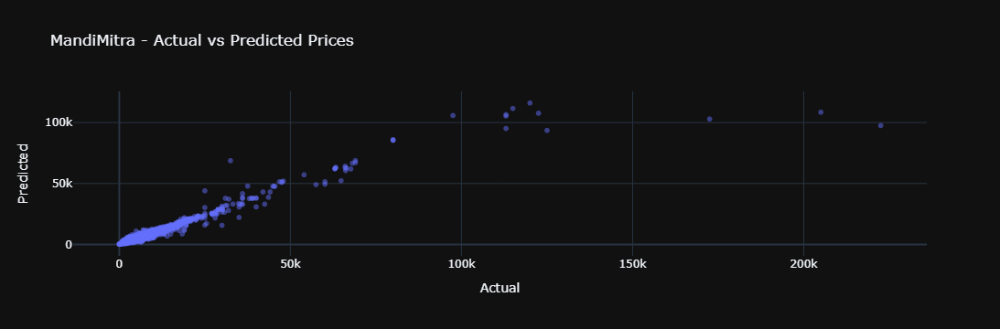

In [50]:
import plotly.express as px

plot_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': cat_predictions
})

fig = px.scatter(
    plot_df,
    x='Actual',
    y='Predicted',
    opacity=0.5,
    title='MandiMitra - Actual vs Predicted Prices',
    template='plotly_dark'
)

fig.show()

In [51]:
importance = pd.DataFrame({
    'Feature': all_features,
    'Importance': cat_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance.head(20))

,Feature,Importance
9,Modal_Price,20.390441
8,Max_Price,17.021317
7,Min_Price,12.896774
11,Lag_2,8.085966
14,Rolling_Mean_3,7.547491
10,Lag_1,7.419342
12,Lag_3,6.410166
13,Lag_7,5.488723
15,Rolling_Mean_7,3.231563
4,Week_of_Year,2.018692


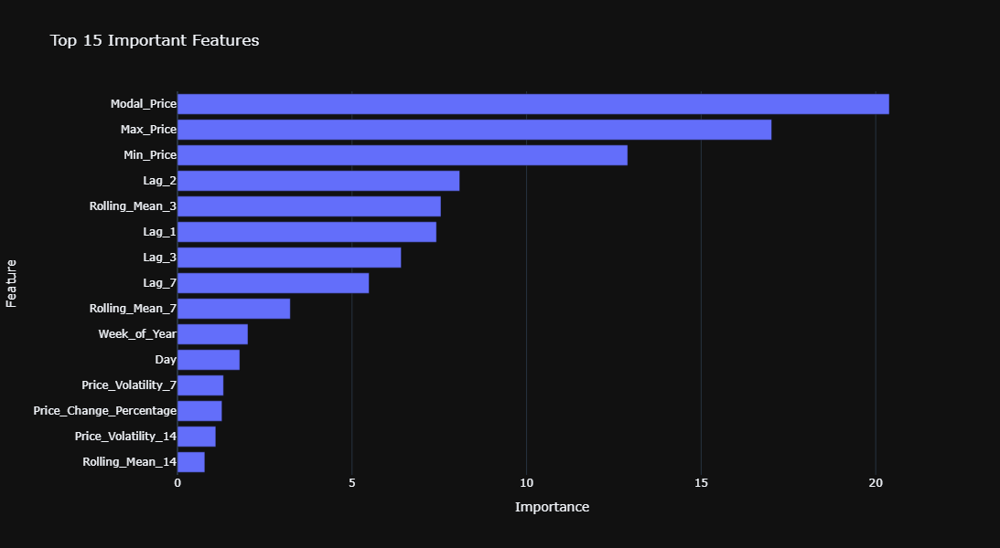

In [52]:
fig = px.bar(
    importance.head(15),
    x='Importance',
    y='Feature',
    orientation='h',
    title='Top 15 Important Features',
    template='plotly_dark'
)

fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    height=600
)

fig.show()

In [53]:
import os
import json

os.makedirs('models', exist_ok=True)

cat_model.save_model(
    'models/mandimitra_catboost.cbm'
)

with open('models/model_features.json', 'w') as f:
    json.dump(all_features, f)

with open('models/categorical_features.json', 'w') as f:
    json.dump(categorical_features, f)

print("MandiMitra Model Saved Successfully!")

MandiMitra Model Saved Successfully!


In [54]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import time

In [55]:
numerical_features = [
    'Year', 'Month', 'Day',
    'Day_of_Week', 'Week_of_Year',
    'Quarter', 'Is_Weekend',
    'Min_Price', 'Max_Price', 'Modal_Price',
    'Lag_1', 'Lag_2', 'Lag_3', 'Lag_7',
    'Rolling_Mean_3', 'Rolling_Mean_7',
    'Rolling_Mean_14',
    'Price_Change',
    'Price_Change_Percentage',
    'Price_Volatility_7',
    'Price_Volatility_14'
]

categorical_features = [
    'State',
    'District',
    'Market',
    'Commodity',
    'Variety',
    'Grade'
]

print("Numerical Features:", len(numerical_features))

print("Categorical Features:", len(categorical_features))

print("Training Records:", len(X_train))

Numerical Features: 21
Categorical Features: 6
Training Records: 99326


In [56]:
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=50
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [57]:
# STEP 52 - Optimized Random Forest

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import time

# Sample training data
X_rf = X_train.sample(
    n=min(100000, len(X_train)),
    random_state=42
)

y_rf = y_train.loc[X_rf.index]

# Create optimized model
rf_model = Pipeline([
    ('preprocessor', preprocessor),

    ('model', RandomForestRegressor(
        n_estimators=80,
        max_depth=12,
        min_samples_leaf=5,
        max_features=0.7,
        n_jobs=-1,
        random_state=42
    ))
])

# Training
start_time = time.time()

rf_model.fit(X_rf, y_rf)

rf_time = time.time() - start_time

print("Random Forest Training Completed!")

print("Training Records:", len(X_rf))

print("Training Time:", round(rf_time, 2), "seconds")

Random Forest Training Completed!
Training Records: 99326
Training Time: 72.73 seconds


In [58]:
rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("RANDOM FOREST RESULTS")

print("MAE:", round(rf_mae, 2))

print("RMSE:", round(rf_rmse, 2))

print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST RESULTS
MAE: 308.86
RMSE: 1531.86
R2 Score: 0.9265


In [59]:
xgb_model = Pipeline([
    ('preprocessor', preprocessor),

    ('model', XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    ))
])

start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_time = time.time() - start_time

print("XGBoost Training Completed!")

print("Training Time:", round(xgb_time, 2), "seconds")

XGBoost Training Completed!
Training Time: 11.24 seconds


In [60]:
xgb_predictions = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)

xgb_r2 = r2_score(
    y_test,
    xgb_predictions
)

print("XGBOOST RESULTS")

print("MAE:", round(xgb_mae, 2))

print("RMSE:", round(xgb_rmse, 2))

print("R2 Score:", round(xgb_r2, 4))

XGBOOST RESULTS
MAE: 367.94
RMSE: 2451.72
R2 Score: 0.8118


In [61]:
model_comparison = pd.DataFrame({

    'Model': [
        'Baseline',
        'CatBoost',
        'Random Forest',
        'XGBoost'
    ],

    'MAE': [
        baseline_mae,
        mae,
        rf_mae,
        xgb_mae
    ],

    'RMSE': [
        baseline_rmse,
        rmse,
        rf_rmse,
        xgb_rmse
    ],

    'R2 Score': [
        baseline_r2,
        r2,
        rf_r2,
        xgb_r2
    ]

})

model_comparison = model_comparison.sort_values(
    by='RMSE',
    ascending=True
)

display(model_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Baseline,283.3621,1190.8653,0.9556
2,Random Forest,308.8555,1531.8553,0.9265
1,CatBoost,348.2041,1590.9054,0.9207
3,XGBoost,367.9361,2451.7154,0.8118


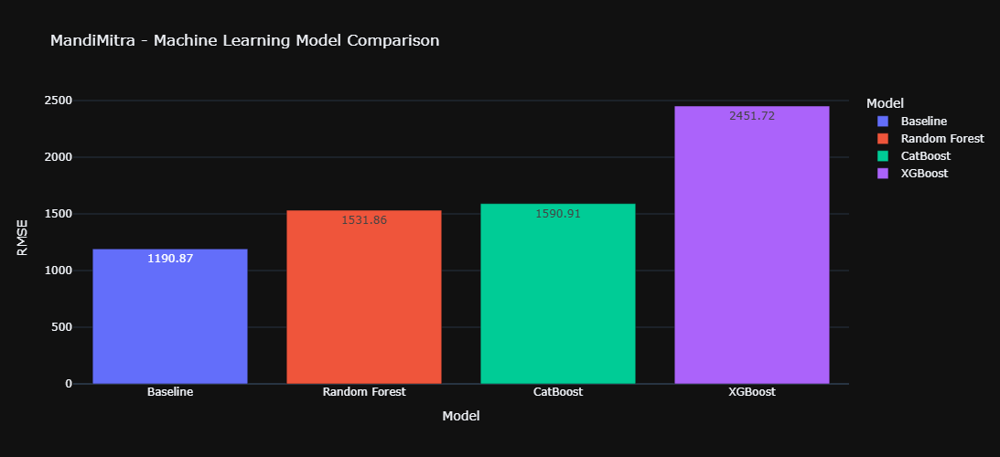

In [62]:
import plotly.express as px

fig = px.bar(
    model_comparison,
    x='Model',
    y='RMSE',
    color='Model',
    title='MandiMitra - Machine Learning Model Comparison',
    template='plotly_dark',
    text_auto='.2f'
)

fig.update_layout(height=500)

fig.show()

In [63]:
best_model_name = model_comparison.iloc[0]['Model']

print("Best Model:", best_model_name)

print(
    "Lowest RMSE:",
    round(model_comparison.iloc[0]['RMSE'], 2)
)

Best Model: Baseline
Lowest RMSE: 1190.87


In [64]:
import joblib
import os

os.makedirs('models', exist_ok=True)

joblib.dump(
    rf_model,
    'models/random_forest_model.pkl'
)

joblib.dump(
    xgb_model,
    'models/xgboost_model.pkl'
)

cat_model.save_model(
    'models/catboost_model.cbm'
)

print("All Models Saved Successfully!")

All Models Saved Successfully!


In [65]:
# Select the same test sample for every model

X_eval = X_test.sample(
    n=min(20000, len(X_test)),
    random_state=42
)

y_eval = y_test.loc[X_eval.index]

# Baseline predictions
baseline_pred = X_eval['Modal_Price'].values

# Random Forest predictions
rf_pred = rf_model.predict(X_eval)

# XGBoost predictions
xgb_pred = xgb_model.predict(X_eval)

# CatBoost predictions
cat_pred = cat_model.predict(X_eval)

print("All predictions generated on identical test records!")

All predictions generated on identical test records!


In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

predictions = {
    'Baseline': baseline_pred,
    'Random Forest': rf_pred,
    'XGBoost': xgb_pred,
    'CatBoost': cat_pred
}

results = []

for name, pred in predictions.items():

    results.append({
        'Model': name,

        'MAE': mean_absolute_error(
            y_eval, pred
        ),

        'RMSE': np.sqrt(
            mean_squared_error(y_eval, pred)
        ),

        'R2': r2_score(
            y_eval, pred
        )
    })

final_comparison = pd.DataFrame(results)

display(
    final_comparison.sort_values(
        'RMSE'
    ).round(3)
)

,Model,MAE,RMSE,R2
0,Baseline,283.362,1190.865,0.956
1,Random Forest,308.855,1531.855,0.927
3,CatBoost,348.204,1590.905,0.921
2,XGBoost,367.936,2451.715,0.812


In [67]:
commodity_results = model_df.loc[
    X_eval.index,
    ['Commodity', 'State', 'District', 'Market']
].copy()

commodity_results['Actual_Price'] = y_eval.values

commodity_results['Predicted_Price'] = cat_pred

commodity_results['Absolute_Error'] = abs(
    commodity_results['Actual_Price'] -
    commodity_results['Predicted_Price']
)

commodity_performance = (
    commodity_results
    .groupby('Commodity')
    .agg(
        MAE=('Absolute_Error', 'mean'),
        Average_Price=('Actual_Price', 'mean'),
        Total_Records=('Actual_Price', 'count')
    )
    .reset_index()
)

commodity_performance = commodity_performance.sort_values(
    'MAE'
)

display(commodity_performance.head(20))

,Commodity,MAE,Average_Price,Total_Records
127,Other green and fresh vegetables,3.510807,700.000000,3
154,Season Leaves,12.374048,900.000000,1
3,Amranthas Red,39.694606,2500.000000,2
183,White Pumpkin,41.841624,1400.000000,2
184,Wood,47.048911,537.660000,8
134,Peas (Dry),57.442508,6818.750000,4
166,Suvarna Gadde,57.473292,3100.000000,3
23,Big Gram,71.685124,5010.750000,4
72,Green Fodder,78.196695,326.666667,3
59,Dry Fodder,82.610993,750.000000,1


In [68]:
display(
    commodity_performance.sort_values(
        'MAE',
        ascending=False
    ).head(20)
)

,Commodity,MAE,Average_Price,Total_Records
91,Kakada,62871.542389,164000.000000,5
187,poppy seeds,14193.918049,118250.000000,4
87,Jasmine,12484.884005,44500.000000,5
145,Raibel,12117.004512,28500.000000,2
11,Asparagus,5342.559657,25000.000000,1
35,Cashewnuts,4787.520360,79600.000000,3
27,Black pepper,3856.217407,67148.352941,17
112,Marigold (Calcutta),3398.458313,15653.846154,13
149,Rose (Local),2982.798330,20384.615385,13
6,Arecanut (Betelnut/Supari),2919.424424,36859.437500,32


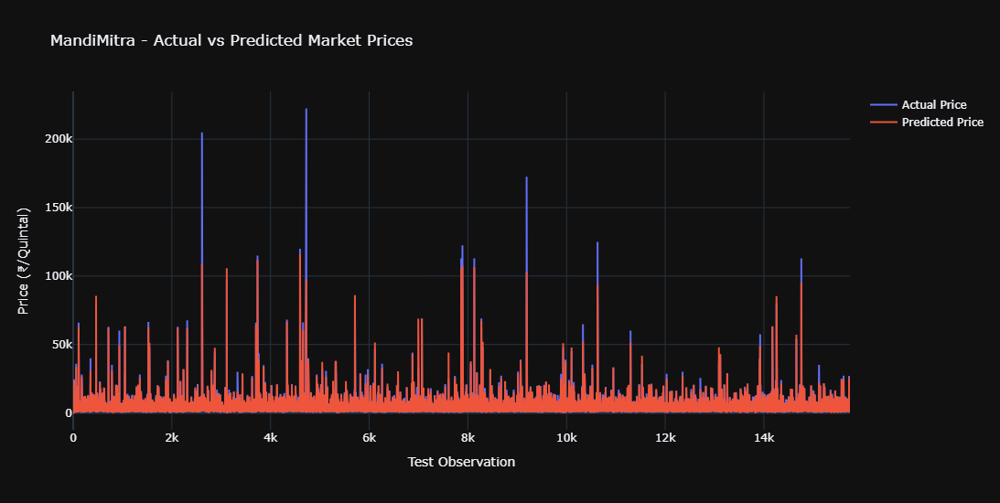

In [69]:
import plotly.graph_objects as go

comparison_plot = pd.DataFrame({
    'Actual': y_eval.values,
    'Predicted': cat_pred
})

comparison_plot = comparison_plot.reset_index(drop=True)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        y=comparison_plot['Actual'],
        mode='lines',
        name='Actual Price'
    )
)

fig.add_trace(
    go.Scatter(
        y=comparison_plot['Predicted'],
        mode='lines',
        name='Predicted Price'
    )
)

fig.update_layout(
    title='MandiMitra - Actual vs Predicted Market Prices',
    xaxis_title='Test Observation',
    yaxis_title='Price (₹/Quintal)',
    template='plotly_dark',
    height=550
)

fig.show()

In [70]:
import plotly.express as px

def compare_mandis(commodity_name):

    filtered = model_df[
        model_df['Commodity'].str.lower()
        == commodity_name.lower()
    ]

    mandi_prices = (
        filtered.groupby(
            ['State', 'District', 'Market']
        )
        .agg(
            Average_Price=('Modal_Price', 'mean'),
            Records=('Modal_Price', 'count')
        )
        .reset_index()
    )

    mandi_prices = mandi_prices[
        mandi_prices['Records'] >= 3
    ]

    mandi_prices = mandi_prices.sort_values(
        'Average_Price',
        ascending=False
    )

    display(mandi_prices.head(20))

    fig = px.bar(
        mandi_prices.head(20),
        x='Market',
        y='Average_Price',
        color='State',
        hover_data=['District', 'Records'],
        title=f'{commodity_name} - Mandi Price Comparison',
        template='plotly_dark'
    )

    fig.update_layout(height=550)

    fig.show()

,State,District,Market,Average_Price,Records
281,Tamil Nadu,Pudukkottai,Karambakkudi (Uzhavar Sandhai ) APMC,4625.000000,4
134,Kerala,Kollam,Kottarakkara APMC,4600.000000,3
335,Tamil Nadu,Virudhunagar,Virudhunagar (Uzhavar Sandhai ) APMC,4512.500000,16
127,Kerala,Idukki,Vandiperiyar APMC,4428.571429,7
282,Tamil Nadu,Ramanathapuram,Paramakudi (Uzhavar Sandhai ) APMC,4008.333333,12
252,Tamil Nadu,Coimbatore,Pollachi (Uzhavar Sandhai ) APMC,4000.000000,24
283,Tamil Nadu,Ramanathapuram,Ramanathapuram (Uzhavar Sandhai ) APMC,3976.923077,13
275,Tamil Nadu,Nagapattinam,Mayiladuthurai (Uzhavar Sandhai ) APMC,3975.000000,20
264,Tamil Nadu,Kallakuruchi,Sankarapuram (Uzhavar Sandhai ) APMC,3913.043478,23
253,Tamil Nadu,Coimbatore,Sulur (Uzhavar Sandhai ) APMC,3833.333333,12


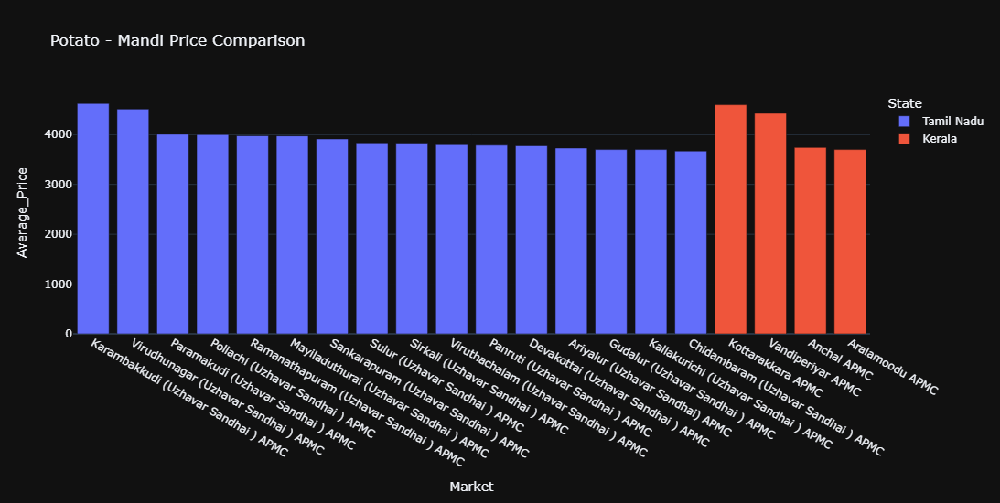

In [71]:
compare_mandis('Potato')

In [72]:
# Save final processed dataset

model_df.to_csv(
    'MandiMitra_Dashboard_Data.csv',
    index=False
)

print("Dashboard Dataset Saved!")

print("Dataset Shape:", model_df.shape)

Dashboard Dataset Saved!
Dataset Shape: (165418, 31)


In [73]:
import os
import json

os.makedirs('models', exist_ok=True)

cat_model.save_model(
    'models/mandimitra_catboost.cbm'
)

with open('models/model_features.json', 'w') as f:
    json.dump(all_features, f)

with open('models/categorical_features.json', 'w') as f:
    json.dump(categorical_features, f)

print("Dashboard Models and Features Saved!")

Dashboard Models and Features Saved!


In [74]:
import os

print("PROJECT DIRECTORY")

print(os.getcwd())

print("\nMAIN FILES")

print(os.listdir())

print("\nMODEL FILES")

print(os.listdir("models"))

PROJECT DIRECTORY
C:\Users\amanr\Desktop\Mandimintra(Main)

MAIN FILES
['.ipynb_checkpoints', 'All_India_Mandi_2026.csv', 'app.py', 'catboost_info', 'data', 'datasets', 'MandiMitra_Dashboard_Data.csv', 'MandiMitra_Feature_Engineered.csv', 'MandiMitra_India_EDA.csv', 'maps', 'models', 'Project(2)_with_exact_future_date_prediction.ipynb', 'ResearchIeee.pdf']

MODEL FILES
['catboost_model.cbm', 'categorical_features.json', 'mandimitra_catboost.cbm', 'mandimitra_features.json', 'model_features.json', 'random_forest_model.pkl', 'xgboost_model.pkl']


In [75]:
import requests
import json
import os

os.makedirs("maps", exist_ok=True)

url = "https://cdn.jsdelivr.net/gh/udit-001/india-maps-data@2884453/geojson/india.geojson"

response = requests.get(url, timeout=60)

response.raise_for_status()

india_geojson = response.json()

with open("maps/india_states.geojson", "w", encoding="utf-8") as f:
    json.dump(india_geojson, f)

print("India GeoJSON downloaded successfully!")

print("Total geographical features:",
      len(india_geojson["features"]))

print("\nAvailable properties:")

print(
    india_geojson["features"][0]["properties"]
)

India GeoJSON downloaded successfully!
Total geographical features: 760

Available properties:
{'district': 'Aizawl', 'dt_code': '261', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}


In [76]:
with open("maps/india_states.geojson", "r", encoding="utf-8") as f:
    geo_data = json.load(f)

for feature in geo_data["features"][:5]:

    print(feature["properties"])

{'district': 'Aizawl', 'dt_code': '261', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Champhai', 'dt_code': '262', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Kolasib', 'dt_code': '263', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Lawngtlai', 'dt_code': '264', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Lunglei', 'dt_code': '265', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}


In [77]:
print("DATASET STATES")

print(sorted(df["State"].dropna().unique()))

print("\nMAP STATES")

for feature in geo_data["features"]:

    print(feature["properties"])

DATASET STATES
['Andaman and Nicobar', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chattisgarh', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'NCT of Delhi', 'Nagaland', 'Odisha', 'Pondicherry', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

MAP STATES
{'district': 'Aizawl', 'dt_code': '261', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Champhai', 'dt_code': '262', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Kolasib', 'dt_code': '263', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Lawngtlai', 'dt_code': '264', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Lunglei', 'dt_code': '265', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Mamit', 'dt_code': '266', 'st_nm': 'Mizoram', 'st_c

In [78]:
import pandas as pd
import json
import os

# Load India GeoJSON
geojson_path = "maps/india_states.geojson"

if not os.path.exists(geojson_path):
    print("GeoJSON file not found. Complete Step 73 first.")

else:

    with open(geojson_path, "r", encoding="utf-8") as f:
        geo_data = json.load(f)

    # Display GeoJSON properties
    print("GEOJSON PROPERTY NAMES")

    print(
        list(geo_data["features"][0]["properties"].keys())
    )

    # Extract state names
    map_states = []

    for feature in geo_data["features"]:

        properties = feature["properties"]

        print(properties)

        map_states.append(properties)

    print("\nTOTAL MAP FEATURES:", len(map_states))

    # Dataset states
    print("\nDATASET STATES")

    dataset_states = sorted(
        df["State"].dropna().astype(str).unique()
    )

    for state in dataset_states:
        print(state)

    print("\nTOTAL DATASET STATES:", len(dataset_states))

GEOJSON PROPERTY NAMES
['district', 'dt_code', 'st_nm', 'st_code', 'year']
{'district': 'Aizawl', 'dt_code': '261', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Champhai', 'dt_code': '262', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Kolasib', 'dt_code': '263', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Lawngtlai', 'dt_code': '264', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Lunglei', 'dt_code': '265', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Mamit', 'dt_code': '266', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Saiha', 'dt_code': '267', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Serchhip', 'dt_code': '268', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2011_c'}
{'district': 'Khawzawl', 'dt_code': '996', 'st_nm': 'Mizoram', 'st_code': '15', 'year': '2019'}
{'district': 'Hnahthial', 'dt_code': '994', 'st_nm': '

In [79]:
import pandas as pd
import json

# ==========================================
# LOAD GEOJSON
# ==========================================

with open("maps/india_states.geojson", "r", encoding="utf-8") as f:
    geo_data = json.load(f)


# ==========================================
# EXTRACT GEOGRAPHICAL INFORMATION
# ==========================================

map_records = []

for feature in geo_data["features"]:

    properties = feature.get("properties", {})

    map_records.append({

        "State": properties.get("st_nm", "Unknown"),

        "District": properties.get("district", "Unknown"),

        "District_Code": properties.get(
            "dt_code",
            properties.get("dtcode", None)
        ),

        "State_Code": properties.get("st_code", None),

        "Year": properties.get("year", None)

    })


# ==========================================
# CREATE DATAFRAME
# ==========================================

map_df = pd.DataFrame(map_records)

# Remove records without geographical names

map_df = map_df[
    (map_df["State"] != "Unknown") &
    (map_df["District"] != "Unknown")
].copy()

# Remove duplicate districts

map_df = map_df.drop_duplicates(
    subset=["State", "District"]
).reset_index(drop=True)


# ==========================================
# DISPLAY RESULTS
# ==========================================

print("GEOJSON ANALYSIS")

print("Total Districts:", len(map_df))

print("Total States:", map_df["State"].nunique())

print("\nINDIAN STATES:")

print(sorted(map_df["State"].unique()))

print("\nFIRST 20 DISTRICTS:")

display(map_df.head(20))

print("\nMISSING VALUES:")

display(map_df.isnull().sum())

GEOJSON ANALYSIS
Total Districts: 724
Total States: 36

INDIAN STATES:
['Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli and Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

FIRST 20 DISTRICTS:


,State,District,District_Code,State_Code,Year
0,Mizoram,Aizawl,261,15,2011_c
1,Mizoram,Champhai,262,15,2011_c
2,Mizoram,Kolasib,263,15,2011_c
3,Mizoram,Lawngtlai,264,15,2011_c
4,Mizoram,Lunglei,265,15,2011_c
5,Mizoram,Mamit,266,15,2011_c
6,Mizoram,Saiha,267,15,2011_c
7,Mizoram,Serchhip,268,15,2011_c
8,Mizoram,Khawzawl,996,15,2019
9,Mizoram,Hnahthial,994,15,2019



MISSING VALUES:


State            0
District         0
District_Code    1
State_Code       0
Year             0
dtype: int64

In [80]:
# Normalize state names

dataset_states = set(
    df["State"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .unique()
)

map_states = set(
    map_df["State"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .unique()
)

# Compare states

matched_states = dataset_states.intersection(map_states)

unmatched_dataset = dataset_states - map_states

unmatched_map = map_states - dataset_states

print("MATCHED STATES:", len(matched_states))

print("\nMATCHED STATE NAMES:")

print(sorted(matched_states))

print("\nUNMATCHED DATASET STATES:")

print(sorted(unmatched_dataset))

print("\nUNMATCHED MAP STATES:")

print(sorted(unmatched_map))

MATCHED STATES: 26

MATCHED STATE NAMES:
['andhra pradesh', 'arunachal pradesh', 'assam', 'bihar', 'chandigarh', 'goa', 'gujarat', 'haryana', 'himachal pradesh', 'jammu and kashmir', 'karnataka', 'kerala', 'madhya pradesh', 'maharashtra', 'manipur', 'meghalaya', 'nagaland', 'odisha', 'punjab', 'rajasthan', 'tamil nadu', 'telangana', 'tripura', 'uttar pradesh', 'uttarakhand', 'west bengal']

UNMATCHED DATASET STATES:
['andaman and nicobar', 'chattisgarh', 'nct of delhi', 'pondicherry']

UNMATCHED MAP STATES:
['andaman and nicobar islands', 'chhattisgarh', 'dadra and nagar haveli and daman and diu', 'delhi', 'jharkhand', 'ladakh', 'lakshadweep', 'mizoram', 'puducherry', 'sikkim']


In [81]:
district_prices = (

    df.groupby(
        ["State", "District"]
    )

    .agg(

        Average_Price=("Modal_Price", "mean"),

        Minimum_Price=("Modal_Price", "min"),

        Maximum_Price=("Modal_Price", "max"),

        Total_Records=("Modal_Price", "count"),

        Total_Commodities=("Commodity", "nunique")

    )

    .reset_index()

)

print("DISTRICT PRICE ANALYSIS")

display(district_prices.head(20))

print("\nTotal District Records:", len(district_prices))

DISTRICT PRICE ANALYSIS


,State,District,Average_Price,Minimum_Price,Maximum_Price,Total_Records,Total_Commodities
0,Andaman and Nicobar,North and Middle Andaman,5360.074627,1500.0,26000.0,268,33
1,Andaman and Nicobar,South Andaman,4933.333333,3000.0,10000.0,15,9
2,Andhra Pradesh,Alluri Sitharama Raju,3245.454545,2370.0,12000.0,11,2
3,Andhra Pradesh,Anantapur,7797.872340,1100.0,21000.0,47,3
4,Andhra Pradesh,Annamayya,1380.000000,800.0,3800.0,33,1
5,Andhra Pradesh,Chittor,2011.414791,600.0,5500.0,311,10
6,Andhra Pradesh,Cuddapah,7886.764706,300.0,13112.0,51,3
7,Andhra Pradesh,East Godavari,2644.459916,1320.0,4300.0,237,2
8,Andhra Pradesh,Guntur,14635.313333,1700.0,23000.0,150,3
9,Andhra Pradesh,Krishna,2350.000000,2350.0,2350.0,5,1



Total District Records: 547


In [82]:
import pandas as pd
import json
import re

# ==========================================
# 1. NORMALIZE TEXT
# ==========================================

def normalize_name(value):

    if pd.isna(value):
        return ""

    value = str(value).strip().lower()

    value = re.sub(r'[^a-z0-9]', '', value)

    return value


# ==========================================
# 2. STATE NAME MAPPING
# ==========================================

state_aliases = {

    "orissa": "odisha",

    "uttaranchal": "uttarakhand",

    "nctofdelhi": "delhi",

    "jammuandkashmir": "jammuandkashmir",

    "pondicherry": "puducherry"

}


def normalize_state(value):

    name = normalize_name(value)

    return state_aliases.get(name, name)


# ==========================================
# 3. NORMALIZE DATASET
# ==========================================

df_map = df.copy()

df_map["State_Key"] = df_map["State"].apply(
    normalize_state
)

df_map["District_Key"] = df_map["District"].apply(
    normalize_name
)


# ==========================================
# 4. NORMALIZE GEOJSON DATA
# ==========================================

map_df["State_Key"] = map_df["State"].apply(
    normalize_state
)

map_df["District_Key"] = map_df["District"].apply(
    normalize_name
)


# ==========================================
# 5. CREATE UNIQUE MAP KEY
# ==========================================

df_map["Map_Key"] = (
    df_map["State_Key"] + "_" +
    df_map["District_Key"]
)

map_df["Map_Key"] = (
    map_df["State_Key"] + "_" +
    map_df["District_Key"]
)


# ==========================================
# 6. CHECK MATCHING
# ==========================================

dataset_keys = set(df_map["Map_Key"])

geojson_keys = set(map_df["Map_Key"])

matched = dataset_keys.intersection(geojson_keys)

unmatched_dataset = dataset_keys - geojson_keys

unmatched_geojson = geojson_keys - dataset_keys

print("GEOGRAPHICAL MATCHING REPORT")

print("Dataset Districts:", len(dataset_keys))

print("GeoJSON Districts:", len(geojson_keys))

print("Matched Districts:", len(matched))

print("Unmatched Dataset Districts:", len(unmatched_dataset))

print("Unmatched GeoJSON Districts:", len(unmatched_geojson))

print(
    "Matching Percentage:",
    round(len(matched) / max(len(dataset_keys), 1) * 100, 2),
    "%"
)


# ==========================================
# 7. DISPLAY UNMATCHED DISTRICTS
# ==========================================

print("\nUNMATCHED DATASET DISTRICTS")

display(
    df_map[
        df_map["Map_Key"].isin(unmatched_dataset)
    ][["State", "District"]]
    .drop_duplicates()
    .head(50)
)

GEOGRAPHICAL MATCHING REPORT
Dataset Districts: 547
GeoJSON Districts: 724
Matched Districts: 393
Unmatched Dataset Districts: 154
Unmatched GeoJSON Districts: 331
Matching Percentage: 71.85 %

UNMATCHED DATASET DISTRICTS


,State,District
6,Uttar Pradesh,Gautam Budh Nagar
10,Rajasthan,Jaipur Rural
13,Karnataka,Karwar (Uttar Kannad)
17,Tamil Nadu,Thiruvannamalai
21,Tamil Nadu,The Nilgiris
25,Karnataka,Davangere
26,Kerala,Kozhikode (Calicut)
34,Haryana,Gurgaon
35,Haryana,Hissar
39,Tamil Nadu,Thiruchirappalli


In [83]:
district_commodity_prices = (

    df_map.groupby(
        [
            "State",
            "District",
            "State_Key",
            "District_Key",
            "Map_Key",
            "Commodity"
        ]
    )

    .agg(

        Average_Price=("Modal_Price", "mean"),

        Minimum_Price=("Modal_Price", "min"),

        Maximum_Price=("Modal_Price", "max"),

        Total_Records=("Modal_Price", "count"),

        Total_Mandis=("Market", "nunique")

    )

    .reset_index()

)

print("District Commodity Analysis")

display(
    district_commodity_prices.head(20)
)

print(
    "\nTotal Aggregated Records:",
    len(district_commodity_prices)
)

District Commodity Analysis


,State,District,State_Key,District_Key,Map_Key,Commodity,Average_Price,Minimum_Price,Maximum_Price,Total_Records,Total_Mandis
0,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Ashgourd,2944.444444,2500.0,3000.0,9,1
1,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Banana,4500.000000,4500.0,4500.0,8,1
2,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Banana - Green,1750.000000,1500.0,2000.0,8,1
3,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Bhindi (Ladies Finger),3055.555556,2000.0,4500.0,9,1
4,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Bitter gourd,6375.000000,6000.0,7000.0,8,1
5,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Black Gram (Urd Beans)(Whole),9400.000000,8500.0,9500.0,10,1
6,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Bottle gourd,2950.000000,2000.0,3500.0,10,1
7,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Brinjal,3791.666667,3000.0,5000.0,12,1
8,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Cabbage,3583.333333,2000.0,6000.0,6,1
9,Andaman and Nicobar,North and Middle Andaman,andamanandnicobar,northandmiddleandaman,andamanandnicobar_northandmiddleandaman,Cauliflower,5541.666667,2500.0,7000.0,12,1



Total Aggregated Records: 15166


In [84]:
import copy
import json

# Copy original GeoJSON

interactive_geojson = copy.deepcopy(geo_data)

# Add unique geographical identifier

for feature in interactive_geojson["features"]:

    properties = feature["properties"]

    state = properties.get("st_nm", "")

    district = properties.get("district", "")

    map_key = (
        normalize_state(state) + "_" +
        normalize_name(district)
    )

    properties["map_key"] = map_key


# Save updated GeoJSON

with open(
    "maps/india_interactive.geojson",
    "w",
    encoding="utf-8"
) as f:

    json.dump(interactive_geojson, f)

print("Interactive GeoJSON created successfully!")

print("Total geographical features:",
      len(interactive_geojson["features"]))

Interactive GeoJSON created successfully!
Total geographical features: 760


In [85]:
# ==========================================
# CHECK GEOJSON FEATURES
# ==========================================

print("TOTAL GEOJSON FEATURES:",
      len(interactive_geojson["features"]))

print("\nTOTAL GEOJSON DISTRICTS:",
      map_df["District"].nunique())

print("TOTAL GEOJSON STATES:",
      map_df["State"].nunique())


# ==========================================
# CHECK MATCHED DISTRICTS
# ==========================================

print("\nMATCHED DISTRICTS:",
      len(matched))

print("\nMATCHED DISTRICT NAMES:")

matched_districts = (
    df_map[df_map["Map_Key"].isin(matched)]
    [["State", "District"]]
    .drop_duplicates()
)

display(matched_districts)


# ==========================================
# CHECK COMMODITY COVERAGE
# ==========================================

commodity_coverage = (
    district_commodity_prices[
        district_commodity_prices["Map_Key"].isin(matched)
    ]
    .groupby("Commodity")
    .agg(
        Matched_Districts=("District", "nunique"),
        Records=("Total_Records", "sum")
    )
    .reset_index()
    .sort_values(
        "Matched_Districts",
        ascending=False
    )
)

print("\nCOMMODITY-WISE MAP COVERAGE")

display(commodity_coverage.head(20))

TOTAL GEOJSON FEATURES: 760

TOTAL GEOJSON DISTRICTS: 719
TOTAL GEOJSON STATES: 36

MATCHED DISTRICTS: 393

MATCHED DISTRICT NAMES:


,State,District
0,Maharashtra,Nagpur
1,Gujarat,Anand
2,Tamil Nadu,Kancheepuram
3,Tamil Nadu,Namakkal
4,Tamil Nadu,Pudukkottai
...,...,...
138877,Meghalaya,West Jaintia Hills
139014,Andhra Pradesh,Krishna
143544,Rajasthan,Dungarpur
148002,Meghalaya,West Khasi Hills



COMMODITY-WISE MAP COVERAGE


,Commodity,Matched_Districts,Records
189,Onion,283,15526
216,Potato,280,14253
269,Tomato,278,13616
41,Brinjal,267,12892
45,Cabbage,259,10603
112,Green Chilli,255,12086
54,Cauliflower,255,11181
280,Wheat,217,18082
51,Carrot,210,9687
82,Cucumbar (Kheera),210,8033


In [86]:
print("UNMATCHED DATASET DISTRICTS")

unmatched_table = (
    df_map[
        df_map["Map_Key"].isin(unmatched_dataset)
    ]
    [["State", "District"]]
    .drop_duplicates()
    .sort_values(["State", "District"])
)

display(unmatched_table.head(100))

print(
    "Total unmatched districts:",
    len(unmatched_table)
)

UNMATCHED DATASET DISTRICTS


,State,District
3313,Andaman and Nicobar,North and Middle Andaman
5446,Andaman and Nicobar,South Andaman
128708,Andhra Pradesh,Alluri Sitharama Raju
258,Andhra Pradesh,Annamayya
144,Andhra Pradesh,Chittor
8033,Andhra Pradesh,Cuddapah
11328,Andhra Pradesh,Nellore
8715,Andhra Pradesh,Palnadu
183,Assam,Sibsagar
8059,Bihar,East Champaran/ Motihari


Total unmatched districts: 154


In [87]:
# ==========================================
# FIND BEST COMMODITY FOR INDIA MAP
# ==========================================

matched_data = district_commodity_prices[
    district_commodity_prices["Map_Key"].isin(matched)
].copy()

commodity_coverage = (
    matched_data.groupby("Commodity")
    .agg(
        Total_Districts=("Map_Key", "nunique"),
        Total_States=("State", "nunique"),
        Total_Records=("Total_Records", "sum")
    )
    .reset_index()
    .sort_values(
        "Total_Districts",
        ascending=False
    )
)

print("TOP 20 COMMODITIES BY MAP COVERAGE")

display(commodity_coverage.head(20))


# Select commodity with maximum coverage

best_commodity = commodity_coverage.iloc[0]["Commodity"]

print("\nBEST COMMODITY:", best_commodity)

print(
    "Available Districts:",
    commodity_coverage.iloc[0]["Total_Districts"]
)

print(
    "Available States:",
    commodity_coverage.iloc[0]["Total_States"]
)

TOP 20 COMMODITIES BY MAP COVERAGE


,Commodity,Total_Districts,Total_States,Total_Records
189,Onion,285,25,15526
216,Potato,281,25,14253
269,Tomato,279,23,13616
41,Brinjal,267,24,12892
45,Cabbage,259,23,10603
112,Green Chilli,256,24,12086
54,Cauliflower,255,23,11181
280,Wheat,218,14,18082
51,Carrot,210,22,9687
82,Cucumbar (Kheera),210,22,8033



BEST COMMODITY: Onion
Available Districts: 285
Available States: 25


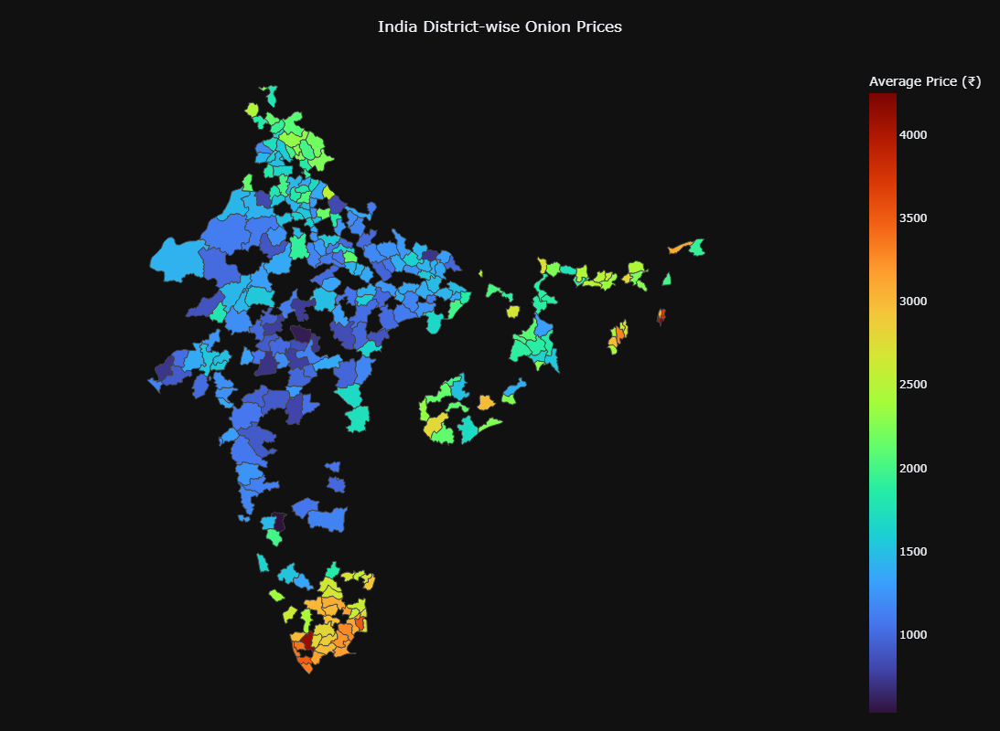

In [88]:
import plotly.express as px
import json

# ==========================================
# FILTER BEST COMMODITY
# ==========================================

map_data = matched_data[
    matched_data["Commodity"] == best_commodity
].copy()


# ==========================================
# CREATE INTERACTIVE MAP
# ==========================================

fig = px.choropleth(

    map_data,

    geojson=interactive_geojson,

    locations="Map_Key",

    featureidkey="properties.map_key",

    color="Average_Price",

    hover_name="District",

    hover_data={
        "State": True,
        "Average_Price": ':.2f',
        "Minimum_Price": ':.2f',
        "Maximum_Price": ':.2f',
        "Total_Mandis": True,
        "Total_Records": True,
        "Map_Key": False
    },

    color_continuous_scale="Turbo",

    title=f"India District-wise {best_commodity} Prices",

    projection="mercator"

)


# ==========================================
# MAP DESIGN
# ==========================================

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    template="plotly_dark",
    height=800,
    title_x=0.5,
    margin=dict(
        l=10,
        r=10,
        t=70,
        b=10
    ),
    coloraxis_colorbar=dict(
        title="Average Price (₹)"
    )
)

fig.show()

In [89]:
print("MAP COVERAGE REPORT")

print("Selected Commodity:", best_commodity)

print("Districts Displayed:", map_data["District"].nunique())

print("States Displayed:", map_data["State"].nunique())

print("Total Market Records:", map_data["Total_Records"].sum())

print("\nSTATE-WISE COVERAGE")

display(
    map_data.groupby("State")
    .agg(
        Districts=("District", "nunique"),
        Average_Price=("Average_Price", "mean"),
        Records=("Total_Records", "sum")
    )
    .sort_values("Districts", ascending=False)
)

MAP COVERAGE REPORT
Selected Commodity: Onion
Districts Displayed: 283
States Displayed: 25
Total Market Records: 15526

STATE-WISE COVERAGE


,Districts,Average_Price,Records
State,,,
Uttar Pradesh,54,1325.758308,942
Madhya Pradesh,28,1030.290410,1056
Tamil Nadu,25,2908.060939,4991
Rajasthan,21,1267.652379,524
West Bengal,16,1918.610500,1114
Haryana,16,1545.306531,1144
Gujarat,14,1231.332468,564
Maharashtra,14,1159.950549,1250
Punjab,13,1662.033509,744


In [90]:
import os
import json

# Create application data directory
os.makedirs("data", exist_ok=True)

# Save district commodity prices
district_commodity_prices.to_csv(
    "data/district_commodity_prices.csv",
    index=False
)

# Save district price summary
district_prices.to_csv(
    "data/district_prices.csv",
    index=False
)

# Save interactive GeoJSON
with open(
    "data/india_interactive.geojson",
    "w",
    encoding="utf-8"
) as f:

    json.dump(interactive_geojson, f)

print("All geographical data saved successfully!")

print("1. district_commodity_prices.csv")
print("2. district_prices.csv")
print("3. india_interactive.geojson")

All geographical data saved successfully!
1. district_commodity_prices.csv
2. district_prices.csv
3. india_interactive.geojson


In [91]:
import os

files = [
    "data/district_commodity_prices.csv",
    "data/district_prices.csv",
    "data/india_interactive.geojson"
]

for file in files:

    if os.path.exists(file):

        print(
            file,
            " | Size:",
            round(os.path.getsize(file) / 1024, 2),
            "KB"
        )

    else:

        print(file, "NOT FOUND")

data/district_commodity_prices.csv  | Size: 1572.25 KB
data/district_prices.csv  | Size: 32.19 KB
data/india_interactive.geojson  | Size: 1171.27 KB


In [92]:
coverage_summary = (
    district_commodity_prices
    .groupby("Commodity")
    .agg(
        States=("State", "nunique"),
        Districts=("District", "nunique"),
        Total_Records=("Total_Records", "sum"),
        Average_Price=("Average_Price", "mean")
    )
    .reset_index()
    .sort_values("Districts", ascending=False)
)

display(coverage_summary.head(20))

coverage_summary.to_csv(
    "data/commodity_coverage.csv",
    index=False
)

,Commodity,States,Districts,Total_Records,Average_Price
225,Potato,27,370,18396,1302.768247
197,Onion,26,369,20064,1752.956425
285,Tomato,25,366,18193,2036.740030
43,Brinjal,27,354,16834,2202.193965
47,Cabbage,26,341,13754,1475.724621
56,Cauliflower,26,333,14800,1963.259738
115,Green Chilli,27,331,16050,4981.623839
296,Wheat,15,293,20821,2519.057156
85,Cucumbar (Kheera),24,280,10991,2490.387436
53,Carrot,23,280,12884,2158.093813


In [93]:
import os

print("CURRENT PROJECT DIRECTORY:")
print(os.getcwd())

print("\nPROJECT FILES:")

for root, dirs, files in os.walk("."):

    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    level = root.count(os.sep)

    if level > 2:
        continue

    print("\nFolder:", root)

    for file in files:
        print("  ", file)

CURRENT PROJECT DIRECTORY:
C:\Users\amanr\Desktop\Mandimintra(Main)

PROJECT FILES:

Folder: .
   All_India_Mandi_2026.csv
   app.py
   MandiMitra_Dashboard_Data.csv
   MandiMitra_Feature_Engineered.csv
   MandiMitra_India_EDA.csv
   Project(2)_with_exact_future_date_prediction.ipynb
   ResearchIeee.pdf

Folder: .\catboost_info
   catboost_training.json
   learn_error.tsv
   test_error.tsv
   time_left.tsv

Folder: .\catboost_info\learn
   events.out.tfevents

Folder: .\catboost_info\test
   events.out.tfevents

Folder: .\catboost_info\tmp

Folder: .\data
   commodity_coverage.csv
   district_commodity_prices.csv
   district_prices.csv
   india_interactive.geojson

Folder: .\datasets
   All_India_Mandi_2026.csv

Folder: .\maps
   india_interactive.geojson
   india_states.geojson

Folder: .\models
   catboost_model.cbm
   categorical_features.json
   mandimitra_catboost.cbm
   mandimitra_features.json
   model_features.json
   random_forest_model.pkl
   xgboost_model.pkl


In [94]:
import os

required_files = [
    "data/district_commodity_prices.csv",
    "data/district_prices.csv",
    "data/india_interactive.geojson",
    "data/commodity_coverage.csv"
]

for file in required_files:

    if os.path.exists(file):
        print("✅ FOUND:", file)

    else:
        print("❌ MISSING:", file)

✅ FOUND: data/district_commodity_prices.csv
✅ FOUND: data/district_prices.csv
✅ FOUND: data/india_interactive.geojson
✅ FOUND: data/commodity_coverage.csv


In [95]:
import os
from pathlib import Path

# ==========================================
# FILE PATHS
# ==========================================

BASE_DIR = Path.cwd()

DATA_DIR = BASE_DIR / "data"

PRICE_FILE = DATA_DIR / "district_commodity_prices.csv"

GEOJSON_FILE = DATA_DIR / "india_interactive.geojson"

print("BASE DIRECTORY:", BASE_DIR)

print("PRICE FILE:", PRICE_FILE)

print("GEOJSON FILE:", GEOJSON_FILE)

print("PRICE FILE EXISTS:", PRICE_FILE.exists())

print("GEOJSON FILE EXISTS:", GEOJSON_FILE.exists())

BASE DIRECTORY: C:\Users\amanr\Desktop\Mandimintra(Main)
PRICE FILE: C:\Users\amanr\Desktop\Mandimintra(Main)\data\district_commodity_prices.csv
GEOJSON FILE: C:\Users\amanr\Desktop\Mandimintra(Main)\data\india_interactive.geojson
PRICE FILE EXISTS: True
GEOJSON FILE EXISTS: True


In [96]:
# ================================================================
# MANDIMITRA INDIA
# AI-POWERED AGRICULTURAL MARKET INTELLIGENCE SYSTEM
# ================================================================

import os
import json
import warnings
import re

from pathlib import Path

import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings("ignore")


# ================================================================
# 1. PAGE CONFIGURATION
# ================================================================

st.set_page_config(
    page_title="MandiMitra India",
    page_icon="🌾",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ================================================================
# 2. DIRECTORY CONFIGURATION
# ================================================================

# Works in both a Python script and Jupyter environment.

if "__file__" in globals():
    BASE_DIR = Path(__file__).resolve().parent
else:
    BASE_DIR = Path.cwd()

DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"

print("Project Directory:", BASE_DIR)


# ================================================================
# 3. FILE PATHS
# ================================================================

CSV_CANDIDATES = [

    BASE_DIR / "All_India_Mandi_2026.csv",

    BASE_DIR / "MandiMitra_Dashboard_Data.csv",

    BASE_DIR / "datasets" / "All_India_Mandi_2026.csv",

    BASE_DIR / "datasets" / "MandiMitra_Dashboard_Data.csv",

    DATA_DIR / "All_India_Mandi_2026.csv",

    DATA_DIR / "MandiMitra_Dashboard_Data.csv",

    DATA_DIR / "district_commodity_prices.csv"

]

GEOJSON_CANDIDATES = [

    DATA_DIR / "india_interactive.geojson",

    BASE_DIR / "india_interactive.geojson",

    BASE_DIR / "maps" / "india_interactive.geojson",

    BASE_DIR / "india_districts.geojson"

]


# ================================================================
# 4. CUSTOM CSS
# ================================================================

st.markdown("""
<style>

.stApp {
    background-color: #0b1020;
    color: #f8fafc;
}

[data-testid="stSidebar"] {
    background-color: #111a2c;
}

[data-testid="stMetric"] {
    background-color: #172238;
    border: 1px solid #293955;
    padding: 18px;
    border-radius: 14px;
}

[data-testid="stMetricValue"] {
    color: #38bdf8;
}

h1, h2, h3 {
    color: #f8fafc;
}

.stButton button {
    border-radius: 8px;
}

</style>
""", unsafe_allow_html=True)


# ================================================================
# 5. HELPER FUNCTIONS
# ================================================================

def find_file(paths):

    for path in paths:

        if path.exists():
            return path

    return None


def normalize_name(value):

    if pd.isna(value):
        return ""

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).strip().lower()
    )


def money(value):

    if pd.isna(value):
        return "N/A"

    return f"₹{value:,.2f}"


def standardize_columns(df):

    aliases = {

        "State": [
            "state",
            "state_name",
            "st_nm"
        ],

        "District": [
            "district",
            "district_name"
        ],

        "Market": [
            "market",
            "market_name",
            "mandi",
            "apmc"
        ],

        "Commodity": [
            "commodity",
            "commodity_name",
            "crop"
        ],

        "Variety": [
            "variety",
            "variety_name"
        ],

        "Grade": [
            "grade"
        ],

        "Arrival_Date": [
            "arrival_date",
            "date",
            "reported_date"
        ],

        "Min_Price": [
            "min_price",
            "minimum_price"
        ],

        "Max_Price": [
            "max_price",
            "maximum_price"
        ],

        "Modal_Price": [
            "modal_price",
            "model_price",
            "price"
        ],

        "Commodity_Code": [
            "commodity_code"
        ]

    }

    existing = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    rename = {}

    for target, candidates in aliases.items():

        if target not in df.columns:

            for candidate in candidates:

                if candidate in existing:

                    rename[existing[candidate]] = target
                    break

    return df.rename(columns=rename)


# ================================================================
# 6. LOAD DATASET
# ================================================================

@st.cache_data(show_spinner="Loading Indian mandi data...")

def load_data(file_path, modified):

    df = pd.read_csv(
        file_path,
        low_memory=False
    )

    df = standardize_columns(df)

    required_columns = [

        "State",
        "District",
        "Market",
        "Commodity",
        "Modal_Price"

    ]

    missing = [
        c for c in required_columns
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"Missing columns: {missing}"
        )

    # Text columns

    text_columns = [

        "State",
        "District",
        "Market",
        "Commodity",
        "Variety",
        "Grade"

    ]

    for col in text_columns:

        if col not in df.columns:

            df[col] = "Unknown"

        df[col] = (
            df[col]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
        )

    # Numeric columns

    numeric_columns = [

        "Min_Price",
        "Max_Price",
        "Modal_Price"

    ]

    for col in numeric_columns:

        if col not in df.columns:

            df[col] = np.nan

        df[col] = pd.to_numeric(

            df[col].astype(str).str.replace(
                ",", "", regex=False
            ),

            errors="coerce"

        )

    # Date conversion

    if "Arrival_Date" not in df.columns:

        df["Arrival_Date"] = pd.NaT

    df["Arrival_Date"] = pd.to_datetime(

        df["Arrival_Date"],

        errors="coerce",

        dayfirst=True

    )

    # Remove invalid prices

    df = df.dropna(
        subset=["Modal_Price"]
    )

    df = df[
        df["Modal_Price"] >= 0
    ].copy()

    # Map key

    df["Map_Key"] = (

        df["State"].apply(normalize_name)

        + "_"

        + df["District"].apply(normalize_name)

    )

    return df


# ================================================================
# 7. LOAD GEOJSON
# ================================================================

@st.cache_data(show_spinner=False)

def load_geojson(file_path, modified):

    with open(
        file_path,
        "r",
        encoding="utf-8"
    ) as f:

        geo = json.load(f)

    for feature in geo.get("features", []):

        props = feature.setdefault(
            "properties", {}
        )

        state = props.get(
            "st_nm",
            props.get(
                "State",
                props.get("state", "")
            )
        )

        district = props.get(
            "district",
            props.get(
                "District",
                props.get("dt_name", "")
            )
        )

        props["map_key"] = (

            normalize_name(state)

            + "_"

            + normalize_name(district)

        )

    return geo


# ================================================================
# 8. SIDEBAR FILTERS
# ================================================================

def apply_filters(df):

    st.sidebar.markdown("---")

    st.sidebar.subheader(
        "🔎 Market Filters"
    )

    states = [

        "All India"

    ] + sorted(
        df["State"].dropna().unique().tolist()
    )

    state = st.sidebar.selectbox(
        "Select State",
        states
    )

    filtered = df.copy()

    if state != "All India":

        filtered = filtered[
            filtered["State"] == state
        ]

    districts = [

        "All Districts"

    ] + sorted(
        filtered["District"].unique().tolist()
    )

    district = st.sidebar.selectbox(
        "Select District",
        districts
    )

    if district != "All Districts":

        filtered = filtered[
            filtered["District"] == district
        ]

    markets = [

        "All Mandis"

    ] + sorted(
        filtered["Market"].unique().tolist()
    )

    market = st.sidebar.selectbox(
        "Select Mandi",
        markets
    )

    if market != "All Mandis":

        filtered = filtered[
            filtered["Market"] == market
        ]

    commodities = [

        "All Commodities"

    ] + sorted(
        filtered["Commodity"].unique().tolist()
    )

    commodity = st.sidebar.selectbox(
        "Select Commodity",
        commodities
    )

    if commodity != "All Commodities":

        filtered = filtered[
            filtered["Commodity"] == commodity
        ]

    # Date filter

    valid_dates = df["Arrival_Date"].dropna()

    if not valid_dates.empty:

        date_range = st.sidebar.date_input(

            "Select Date Range",

            value=(

                valid_dates.min().date(),

                valid_dates.max().date()

            )

        )

        if isinstance(date_range, tuple) and len(date_range) == 2:

            filtered = filtered[

                filtered["Arrival_Date"].dt.date.between(

                    date_range[0],

                    date_range[1]

                )

            ]

    return filtered


# ================================================================
# 9. INDIA OVERVIEW
# ================================================================

def india_overview(df):

    st.title(
        "🌾 MandiMitra India"
    )

    st.subheader(
        "AI-Powered Agricultural Market Intelligence"
    )

    st.write(
        "Explore Indian agricultural markets, compare mandi "
        "prices and discover data-driven insights."
    )

    if df.empty:

        st.warning(
            "No data available for selected filters."
        )

        return

    # KPI CARDS

    metrics = [

        ("Total Records", f"{len(df):,}"),

        ("States", f"{df['State'].nunique():,}"),

        ("Districts", f"{df['District'].nunique():,}"),

        ("Commodities", f"{df['Commodity'].nunique():,}"),

        ("Mandis", f"{df['Market'].nunique():,}")

    ]

    cols = st.columns(5)

    for col, (label, value) in zip(
        cols,
        metrics
    ):

        col.metric(
            label,
            value
        )

    st.markdown("---")

    # STATE AND COMMODITY CHARTS

    left, right = st.columns(2)

    with left:

        st.subheader(
            "State-wise Average Modal Price"
        )

        state_avg = df.groupby(
            "State",
            as_index=False
        )["Modal_Price"].mean()

        state_avg = state_avg.nlargest(
            15,
            "Modal_Price"
        )

        fig = px.bar(

            state_avg.sort_values(
                "Modal_Price"
            ),

            x="Modal_Price",

            y="State",

            orientation="h",

            color="Modal_Price",

            color_continuous_scale="Turbo",

            template="plotly_dark"

        )

        fig.update_layout(
            height=450,
            coloraxis_showscale=False
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    with right:

        st.subheader(
            "Top 15 Commodities by Average Price"
        )

        commodity_avg = df.groupby(
            "Commodity",
            as_index=False
        )["Modal_Price"].mean()

        commodity_avg = commodity_avg.nlargest(
            15,
            "Modal_Price"
        )

        fig = px.bar(

            commodity_avg.sort_values(
                "Modal_Price"
            ),

            x="Modal_Price",

            y="Commodity",

            orientation="h",

            color="Modal_Price",

            color_continuous_scale="Plasma",

            template="plotly_dark"

        )

        fig.update_layout(
            height=450,
            coloraxis_showscale=False
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    # DAILY TREND

    st.subheader(
        "Daily Agricultural Price Trend"
    )

    dated = df.dropna(
        subset=["Arrival_Date"]
    )

    if not dated.empty:

        trend = dated.groupby(
            "Arrival_Date",
            as_index=False
        )["Modal_Price"].mean()

        fig = px.line(

            trend,

            x="Arrival_Date",

            y="Modal_Price",

            markers=True,

            template="plotly_dark"

        )

        fig.update_layout(
            height=400
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    # TOP MARKETS

    st.subheader(
        "Top 10 Markets by Average Modal Price"
    )

    top_markets = df.groupby(

        ["State", "District", "Market"],

        as_index=False

    ).agg(

        Modal_Price=(
            "Modal_Price",
            "mean"
        ),

        Records=(
            "Modal_Price",
            "size"
        )

    ).nlargest(
        10,
        "Modal_Price"
    )

    st.dataframe(
        top_markets,
        use_container_width=True,
        hide_index=True
    )


# ================================================================
# 10. INTERACTIVE INDIA MAP
# ================================================================

def interactive_map(df, geo):

    st.title(
        "🗺️ Interactive India District Map"
    )

    if geo is None:

        st.warning(
            "District GeoJSON file not found. "
            "Add india_interactive.geojson inside data/."
        )

        return

    commodities = sorted(
        df["Commodity"].unique().tolist()
    )

    if not commodities:

        st.info(
            "No commodity data available."
        )

        return

    col1, col2 = st.columns(2)

    with col1:

        commodity = st.selectbox(
            "Select Commodity",
            commodities,
            key="map_commodity"
        )

    with col2:

        metric = st.selectbox(

            "Select Map Metric",

            [
                "Average_Price",
                "Minimum_Price",
                "Maximum_Price",
                "Records"
            ],

            format_func=lambda x: {

                "Average_Price": "Average Modal Price",

                "Minimum_Price": "Minimum Price",

                "Maximum_Price": "Maximum Price",

                "Records": "Number of Records"

            }[x]

        )

    sub = df[
        df["Commodity"] == commodity
    ]

    summary = sub.groupby(

        ["State", "District", "Map_Key"],

        as_index=False

    ).agg(

        Average_Price=(
            "Modal_Price",
            "mean"
        ),

        Minimum_Price=(
            "Min_Price",
            "min"
        ),

        Maximum_Price=(
            "Max_Price",
            "max"
        ),

        Records=(
            "Modal_Price",
            "size"
        ),

        Mandis=(
            "Market",
            "nunique"
        )

    )

    if summary.empty:

        st.info(
            "No records available."
        )

        return

    fig = px.choropleth(

        summary,

        geojson=geo,

        locations="Map_Key",

        featureidkey="properties.map_key",

        color=metric,

        hover_name="District",

        hover_data=[

            "State",

            "Average_Price",

            "Minimum_Price",

            "Maximum_Price",

            "Records",

            "Mandis"

        ],

        color_continuous_scale="Turbo",

        template="plotly_dark",

        title=f"{commodity} - District-wise Market Intelligence"

    )

    fig.update_geos(

        fitbounds="locations",

        visible=False

    )

    fig.update_layout(

        height=700,

        margin=dict(
            l=0,
            r=0,
            t=60,
            b=0
        )

    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    st.subheader(
        "District-wise Price Summary"
    )

    st.dataframe(

        summary.sort_values(
            "Average_Price",
            ascending=False
        ),

        use_container_width=True,

        hide_index=True

    )


# ================================================================
# 11. MARKET EXPLORER
# ================================================================

def market_explorer(df):

    st.title(
        "🔎 Agricultural Market Explorer"
    )

    if df.empty:

        st.info(
            "No records available."
        )

        return

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Total Records",
        f"{len(df):,}"
    )

    col2.metric(
        "Average Price",
        money(df["Modal_Price"].mean())
    )

    col3.metric(
        "Total Mandis",
        df["Market"].nunique()
    )

    st.subheader(
        "Price Distribution"
    )

    fig = px.histogram(

        df,

        x="Modal_Price",

        nbins=40,

        template="plotly_dark"

    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    st.subheader(
        "Detailed Market Records"
    )

    columns = [

        "State",
        "District",
        "Market",
        "Commodity",
        "Variety",
        "Grade",
        "Arrival_Date",
        "Min_Price",
        "Max_Price",
        "Modal_Price"

    ]

    columns = [
        c for c in columns
        if c in df.columns
    ]

    st.dataframe(
        df[columns],
        use_container_width=True,
        hide_index=True
    )

    st.download_button(

        "📥 Download Filtered Dataset",

        df[columns].to_csv(
            index=False
        ).encode("utf-8"),

        file_name="MandiMitra_Filtered_Data.csv",

        mime="text/csv"

    )


# ================================================================
# 12. COMMODITY INTELLIGENCE
# ================================================================

def commodity_intelligence(df):

    st.title(
        "🌽 Commodity Intelligence"
    )

    commodities = sorted(
        df["Commodity"].unique().tolist()
    )

    if not commodities:

        st.info(
            "No commodities available."
        )

        return

    commodity = st.selectbox(
        "Select Commodity",
        commodities,
        key="commodity_intelligence"
    )

    sub = df[
        df["Commodity"] == commodity
    ]

    c1, c2, c3, c4 = st.columns(4)

    c1.metric(
        "Total Records",
        len(sub)
    )

    c2.metric(
        "Average Price",
        money(sub["Modal_Price"].mean())
    )

    c3.metric(
        "Minimum Price",
        money(sub["Modal_Price"].min())
    )

    c4.metric(
        "Maximum Price",
        money(sub["Modal_Price"].max())
    )

    left, right = st.columns(2)

    with left:

        st.subheader(
            "State-wise Price"
        )

        state_data = sub.groupby(
            "State",
            as_index=False
        )["Modal_Price"].mean()

        fig = px.bar(

            state_data.nlargest(
                15,
                "Modal_Price"
            ),

            x="State",

            y="Modal_Price",

            color="Modal_Price",

            template="plotly_dark"

        )

        fig.update_layout(
            xaxis_tickangle=-45
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    with right:

        st.subheader(
            "Mandi-wise Price"
        )

        mandi_data = sub.groupby(
            ["State", "District", "Market"],
            as_index=False
        )["Modal_Price"].mean()

        fig = px.bar(

            mandi_data.nlargest(
                15,
                "Modal_Price"
            ),

            x="Market",

            y="Modal_Price",

            color="State",

            hover_data=["District"],

            template="plotly_dark"

        )

        fig.update_layout(
            xaxis_tickangle=-45
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    # Historical trend

    dated = sub.dropna(
        subset=["Arrival_Date"]
    )

    if not dated.empty:

        st.subheader(
            "Commodity Historical Trend"
        )

        trend = dated.groupby(
            "Arrival_Date",
            as_index=False
        )["Modal_Price"].mean()

        fig = px.line(

            trend,

            x="Arrival_Date",

            y="Modal_Price",

            markers=True,

            template="plotly_dark"

        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    st.subheader(
        "Commodity Market Details"
    )

    st.dataframe(
        mandi_data.sort_values(
            "Modal_Price",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )


# ================================================================
# 13. MANDI COMPARISON
# ================================================================

def mandi_comparison(df):

    st.title(
        "⚖️ Mandi Price Comparison"
    )

    commodities = sorted(
        df["Commodity"].unique().tolist()
    )

    if not commodities:

        st.info(
            "No commodity data available."
        )

        return

    commodity = st.selectbox(
        "Select Commodity",
        commodities,
        key="comparison_commodity"
    )

    sub = df[
        df["Commodity"] == commodity
    ]

    markets = sorted(
        sub["Market"].unique().tolist()
    )

    selected = st.multiselect(

        "Select Mandis",

        markets,

        default=markets[:min(3, len(markets))]

    )

    if not selected:

        st.warning(
            "Select at least one mandi."
        )

        return

    result = sub[
        sub["Market"].isin(selected)
    ].groupby(

        ["State", "District", "Market"],

        as_index=False

    ).agg(

        Average_Price=(
            "Modal_Price",
            "mean"
        ),

        Minimum_Price=(
            "Min_Price",
            "min"
        ),

        Maximum_Price=(
            "Max_Price",
            "max"
        ),

        Records=(
            "Modal_Price",
            "size"
        )

    )

    fig = px.bar(

        result,

        x="Market",

        y="Average_Price",

        color="State",

        hover_data=[

            "District",

            "Minimum_Price",

            "Maximum_Price",

            "Records"

        ],

        template="plotly_dark"

    )

    fig.update_layout(
        height=450,
        xaxis_tickangle=-35
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    st.dataframe(
        result,
        use_container_width=True,
        hide_index=True
    )


# ================================================================
# 14. PRICE VOLATILITY
# ================================================================

def price_volatility(df):

    st.title(
        "📉 Agricultural Price Volatility"
    )

    result = df.groupby(
        "Commodity"
    )["Modal_Price"].agg(

        ["mean", "std", "count"]

    ).reset_index()

    result.rename(

        columns={

            "mean": "Average_Price",

            "std": "Price_StdDev",

            "count": "Records"

        },

        inplace=True

    )

    result["Volatility_Percentage"] = (

        result["Price_StdDev"]

        / result["Average_Price"].replace(
            0,
            np.nan
        )

    ) * 100

    result = result.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna(
        subset=["Volatility_Percentage"]
    )

    if result.empty:

        st.info(
            "Insufficient data to calculate volatility."
        )

        return

    left, right = st.columns(2)

    with left:

        st.subheader(
            "Most Volatile Commodities"
        )

        volatile = result.nlargest(
            20,
            "Volatility_Percentage"
        )

        fig = px.bar(

            volatile.sort_values(
                "Volatility_Percentage"
            ),

            x="Volatility_Percentage",

            y="Commodity",

            orientation="h",

            color="Volatility_Percentage",

            color_continuous_scale="Turbo",

            template="plotly_dark"

        )

        fig.update_layout(
            height=550
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    with right:

        st.subheader(
            "Volatility vs Average Price"
        )

        fig = px.scatter(

            result,

            x="Average_Price",

            y="Volatility_Percentage",

            size="Records",

            color="Volatility_Percentage",

            hover_name="Commodity",

            template="plotly_dark"

        )

        fig.update_layout(
            height=550
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )

    st.subheader(
        "Volatility Details"
    )

    st.dataframe(

        result.sort_values(
            "Volatility_Percentage",
            ascending=False
        ),

        use_container_width=True,

        hide_index=True

    )


# ================================================================
# 15. AI PRICE PREDICTOR
# ================================================================

def price_predictor(df):

    st.title("🤖 AI Agricultural Price Predictor")
    st.write(
        "Forecast mandi modal prices over a future date range using the trained CatBoost model."
    )

    model_path = find_file([
        MODELS_DIR / "mandimitra_catboost.cbm",
        MODELS_DIR / "catboost_model.cbm",
        MODELS_DIR / "catboost_model.pkl"
    ])
    feature_path = find_file([
        MODELS_DIR / "model_features.json",
        MODELS_DIR / "mandimitra_features.json",
        MODELS_DIR / "features.json"
    ])
    category_path = find_file([
        MODELS_DIR / "categorical_features.json",
        MODELS_DIR / "mandimitra_categorical_features.json"
    ])

    if model_path is None or feature_path is None:
        st.warning("CatBoost model or its feature JSON was not found in models/.")
        return

    try:
        with open(feature_path, "r", encoding="utf-8") as f:
            features = json.load(f)
        if isinstance(features, dict):
            features = features.get("features", features.get("feature_names", []))

        categories = []
        if category_path:
            with open(category_path, "r", encoding="utf-8") as f:
                categories = json.load(f)
            if isinstance(categories, dict):
                categories = categories.get("categorical_features", categories.get("categorical", []))

        from catboost import CatBoostRegressor
        model = CatBoostRegressor()
        model.load_model(str(model_path))
    except Exception as e:
        st.error(f"Model loading error: {e}")
        return

    commodities = sorted(df["Commodity"].dropna().unique().tolist())
    states = sorted(df["State"].dropna().unique().tolist())
    if not commodities or not states:
        st.warning("Commodity or State values are unavailable in the dataset.")
        return

    commodity = st.selectbox("Commodity", commodities, key="predict_commodity")
    state = st.selectbox("State", states, key="predict_state")
    state_data = df[df["State"] == state]
    districts = sorted(state_data["District"].dropna().unique().tolist())
    if not districts:
        st.warning("No districts available for this state.")
        return
    district = st.selectbox("District", districts, key="predict_district")

    selected_data = state_data[
        (state_data["District"] == district) &
        (state_data["Commodity"] == commodity)
    ]
    if selected_data.empty:
        st.warning("No historical records for this selection.")
        return

    markets = sorted(selected_data["Market"].dropna().unique().tolist())
    market = st.selectbox("Mandi", markets, key="predict_market")
    local = selected_data[selected_data["Market"] == market].copy()
    local["Arrival_Date"] = pd.to_datetime(local["Arrival_Date"], errors="coerce")
    local = local.dropna(subset=["Arrival_Date", "Modal_Price"]).sort_values("Arrival_Date")
    if local.empty:
        st.warning("No usable historical prices for this mandi.")
        return

    latest = local.iloc[-1]
    latest_date = pd.Timestamp(latest["Arrival_Date"]).normalize()
    latest_price = float(latest["Modal_Price"])
    st.metric("Latest Modal Price", money(latest_price), help=f"Latest recorded date: {latest_date.date()}")
    st.caption(f"Historical data available through {latest_date.date()}.")

    st.subheader("Predict Price on a Future Date")
    st.caption(
        "Choose the exact date you want to forecast. MandiMitra recursively "
        "estimates each day between the latest historical record and your target date."
    )
    default_target = (latest_date + pd.Timedelta(days=30)).date()
    target_date = st.date_input(
        "Future prediction date",
        value=default_target,
        min_value=(latest_date + pd.Timedelta(days=1)).date(),
        max_value=(latest_date + pd.Timedelta(days=365)).date(),
        key="future_target_date"
    )

    target_timestamp = pd.Timestamp(target_date).normalize()
    forecast_days = (target_timestamp - latest_date).days
    if forecast_days < 1:
        st.error(f"Choose a date after the latest available record ({latest_date.date()}).")
        return
    if forecast_days > 365:
        st.error("The selected date cannot be more than 365 days after the latest historical record.")
        return

    st.info(
        f"Target date: **{target_timestamp.date()}** · "
        f"Forecast horizon: **{forecast_days} calendar days** from the latest record."
    )
    if forecast_days > 90:
        st.warning(
            "This is a long-range forecast (more than 90 days). "
            "Uncertainty can be substantial because future arrivals, weather, "
            "demand and market conditions are not known."
        )

    if not st.button("🚀 Predict Price for Selected Date", type="primary"):
        return

    # Forecast every calendar day up to the selected target date so lag and
    # rolling features can be updated recursively. The target-date row is
    # highlighted in the result.
    history = local.copy().sort_values("Arrival_Date").reset_index(drop=True)
    forecast_rows = []
    start_date = latest_date + pd.Timedelta(days=1)
    end_date = target_timestamp
    forecast_dates = pd.date_range(start_date, end_date, freq="D")

    # Use historical min/modal and max/modal ratios to estimate unknown
    # future min/max prices; these are not observed future market values.
    valid_ratio = history[
        (history["Modal_Price"] > 0) &
        (history["Min_Price"] > 0) &
        (history["Max_Price"] > 0)
    ].tail(60)
    if len(valid_ratio):
        min_ratio = float((valid_ratio["Min_Price"] / valid_ratio["Modal_Price"]).median())
        max_ratio = float((valid_ratio["Max_Price"] / valid_ratio["Modal_Price"]).median())
    else:
        min_ratio, max_ratio = 0.95, 1.05

    missing_required = [c for c in features if c not in history.columns and c not in {
        "Year", "Month", "Day", "Day_of_Week", "Week_of_Year", "Quarter", "Is_Weekend",
        "Lag_1", "Lag_2", "Lag_3", "Lag_7", "Rolling_Mean_3", "Rolling_Mean_7",
        "Rolling_Mean_14", "Price_Change", "Price_Change_Percentage",
        "Price_Volatility_7", "Price_Volatility_14", "Min_Price", "Max_Price", "Modal_Price"
    }]
    if missing_required:
        st.error("Required model inputs are unavailable: " + ", ".join(missing_required))
        st.info("Check that the feature JSON matches the CatBoost model trained in the notebook.")
        return

    try:
        for forecast_date in forecast_dates:
            prices = history["Modal_Price"].astype(float)
            previous_price = float(prices.iloc[-1])
            row = latest.to_dict()

            row.update({
                "State": state, "District": district, "Market": market,
                "Commodity": commodity, "Arrival_Date": forecast_date,
                "Year": forecast_date.year,
                "Month": forecast_date.month,
                "Day": forecast_date.day,
                "Day_of_Week": forecast_date.dayofweek,
                "Week_of_Year": int(forecast_date.isocalendar().week),
                "Quarter": forecast_date.quarter,
                "Is_Weekend": int(forecast_date.dayofweek >= 5),
                "Min_Price": max(0.0, previous_price * min_ratio),
                "Max_Price": max(0.0, previous_price * max_ratio),
                "Modal_Price": previous_price,
                "Lag_1": previous_price,
                "Lag_2": float(prices.iloc[-2]) if len(prices) >= 2 else previous_price,
                "Lag_3": float(prices.iloc[-3]) if len(prices) >= 3 else previous_price,
                "Lag_7": float(prices.iloc[-7]) if len(prices) >= 7 else previous_price,
                "Rolling_Mean_3": float(prices.tail(3).mean()),
                "Rolling_Mean_7": float(prices.tail(7).mean()),
                "Rolling_Mean_14": float(prices.tail(14).mean()),
                "Price_Change": previous_price - float(prices.iloc[-2]) if len(prices) >= 2 else 0.0,
                "Price_Change_Percentage": ((previous_price / float(prices.iloc[-2])) - 1) * 100 if len(prices) >= 2 and float(prices.iloc[-2]) != 0 else 0.0,
                "Price_Volatility_7": float(prices.tail(7).std()) if len(prices) >= 7 else 0.0,
                "Price_Volatility_14": float(prices.tail(14).std()) if len(prices) >= 14 else 0.0
            })

            # Compatibility with alternative date-feature names, if present
            row.update({"day": forecast_date.day, "month": forecast_date.month,
                        "year": forecast_date.year, "DayOfWeek": forecast_date.dayofweek,
                        "day_of_week": forecast_date.dayofweek})

            input_row = {feature: row.get(feature, np.nan) for feature in features}
            X_future = pd.DataFrame([input_row], columns=features)
            for col in categories:
                if col in X_future.columns:
                    X_future[col] = X_future[col].fillna("Unknown").astype(str)

            predicted_price = float(np.asarray(model.predict(X_future)).reshape(-1)[0])
            predicted_price = max(0.0, predicted_price)
            forecast_rows.append({
                "Forecast_Date": forecast_date,
                "Predicted_Modal_Price": predicted_price,
                "Change_From_Previous_Step": predicted_price - previous_price,
                "Change_Percent": ((predicted_price / previous_price) - 1) * 100 if previous_price else 0.0
            })

            # Append the prediction so subsequent days use recursively
            # updated lags and rolling statistics.
            new_history_row = latest.to_dict()
            new_history_row.update({
                "Arrival_Date": forecast_date,
                "Modal_Price": predicted_price,
                "Min_Price": predicted_price * min_ratio,
                "Max_Price": predicted_price * max_ratio
            })
            history = pd.concat([history, pd.DataFrame([new_history_row])], ignore_index=True)

        forecast_df = pd.DataFrame(forecast_rows)
        target_row = forecast_df.loc[
            pd.to_datetime(forecast_df["Forecast_Date"]).dt.normalize() == target_timestamp
        ].iloc[-1]
        target_prediction = float(target_row["Predicted_Modal_Price"])
        total_change = target_prediction - latest_price
        pct_change = ((target_prediction / latest_price) - 1) * 100 if latest_price else 0.0

        c1, c2, c3 = st.columns(3)
        c1.metric("Latest Recorded Price", money(latest_price))
        c2.metric(
            f"Predicted Price · {target_timestamp.strftime('%d %b %Y')}",
            money(target_prediction),
            delta=f"{pct_change:+.2f}% vs latest"
        )
        c3.metric("Expected Price Change", money(total_change), delta=f"{total_change:+,.2f}")

        st.success(
            f"Estimated modal price for {target_timestamp.strftime('%d %B %Y')}: "
            f"**{money(target_prediction)} per quintal**"
        )

        fig = px.line(
            forecast_df, x="Forecast_Date", y="Predicted_Modal_Price",
            markers=True, title=f"{commodity} Price Forecast — {market}",
            template="plotly_dark"
        )
        fig.add_hline(y=latest_price, line_dash="dash", annotation_text="Latest observed price")
        fig.update_layout(xaxis_title="Forecast Date", yaxis_title="Predicted Modal Price (₹/Quintal)", height=500)
        st.plotly_chart(fig, use_container_width=True)

        st.subheader("Date-wise Forecast Results")
        display_df = forecast_df.copy()
        display_df["Forecast_Date"] = display_df["Forecast_Date"].dt.strftime("%Y-%m-%d")
        st.dataframe(display_df, use_container_width=True, hide_index=True)

        csv = forecast_df.to_csv(index=False).encode("utf-8")
        st.download_button(
            "⬇️ Download Forecast CSV", data=csv,
            file_name=f"MandiMitra_{commodity}_{market}_forecast.csv",
            mime="text/csv"
        )

        st.warning(
            "Research estimate only: the model was trained to predict the next available market observation. "
            "This date-range view recursively applies that model to calendar dates. Future Min/Max prices "
            "are estimated from recent historical ratios, and weekends/mandi holidays are not filtered. "
            "Longer-horizon estimates can accumulate error and are not official mandi quotes."
        )

    except Exception as e:
        st.error(f"Forecast generation failed: {e}")


# ================================================================
# 16. MODEL PERFORMANCE
# ================================================================

def model_performance():

    st.title(
        "📊 Machine Learning Model Performance"
    )

    comparison_paths = [

        MODELS_DIR / "model_comparison.csv",

        DATA_DIR / "model_comparison.csv",

        BASE_DIR / "model_comparison.csv"

    ]

    comparison_file = find_file(
        comparison_paths
    )

    if comparison_file is None:

        st.info(
            "Export your model_comparison DataFrame "
            "from Jupyter as model_comparison.csv "
            "and place it inside models/."
        )

        st.markdown("""
        ### Evaluation Metrics

        **MAE:** Mean Absolute Error.

        **RMSE:** Root Mean Squared Error.

        **R² Score:** Coefficient of Determination.

        Lower MAE and RMSE are better.
        Higher R² is generally better.
        """)

        return

    comparison = pd.read_csv(
        comparison_file
    )

    st.subheader(
        "Model Comparison Table"
    )

    st.dataframe(
        comparison,
        use_container_width=True,
        hide_index=True
    )

    if "Model" in comparison.columns:

        metrics = [
            c for c in comparison.columns
            if c in ["MAE", "RMSE", "R2 Score", "R2"]
        ]

        for metric in metrics:

            st.subheader(
                f"{metric} Comparison"
            )

            fig = px.bar(

                comparison,

                x="Model",

                y=metric,

                color="Model",

                template="plotly_dark"

            )

            st.plotly_chart(
                fig,
                use_container_width=True
            )


# ================================================================
# 17. APPLICATION HEADER
# ================================================================

st.sidebar.title(
    "🌾 MandiMitra"
)

st.sidebar.caption(
    "India Agricultural Intelligence"
)


# ================================================================
# 18. LOAD MAIN DATASET
# ================================================================

csv_path = find_file(
    CSV_CANDIDATES
)

if csv_path is None:

    st.error(
        "All India CSV dataset not found."
    )

    st.write(
        "Place All_India_Mandi_2026.csv "
        "inside your project folder or datasets/."
    )

    st.code("""
MandiMitra/
│
├── app.py
├── All_India_Mandi_2026.csv
│
├── data/
│   └── india_interactive.geojson
│
└── models/
    ├── mandimitra_catboost.cbm
    ├── mandimitra_features.json
    └── categorical_features.json
""")

    st.stop()


try:

    df = load_data(

        str(csv_path),

        csv_path.stat().st_mtime

    )

except Exception as e:

    st.error(
        f"Dataset Error: {e}"
    )

    st.stop()


if df.empty:

    st.error(
        "No valid price records found."
    )

    st.stop()


st.sidebar.success(
    f"Loaded: {csv_path.name}"
)

st.sidebar.caption(
    f"{len(df):,} valid records"
)


# ================================================================
# 19. APPLY SIDEBAR FILTERS
# ================================================================

filtered_df = apply_filters(
    df
)


# ================================================================
# 20. LOAD INDIA GEOJSON
# ================================================================

geo_path = find_file(
    GEOJSON_CANDIDATES
)

geo = None

if geo_path:

    try:

        geo = load_geojson(

            str(geo_path),

            geo_path.stat().st_mtime

        )

    except Exception as e:

        st.sidebar.warning(
            f"Map loading issue: {e}"
        )


# ================================================================
# 21. NAVIGATION
# ================================================================

pages = [

    "India Overview",

    "Interactive India Map",

    "Market Explorer",

    "Commodity Intelligence",

    "AI Price Predictor",

    "Mandi Comparison",

    "Price Volatility",

    "Model Performance"

]

page = st.sidebar.radio(
    "NAVIGATION",
    pages
)


# ================================================================
# 22. PAGE ROUTING
# ================================================================

if page == "India Overview":

    india_overview(
        filtered_df
    )

elif page == "Interactive India Map":

    interactive_map(
        filtered_df,
        geo
    )

elif page == "Market Explorer":

    market_explorer(
        filtered_df
    )

elif page == "Commodity Intelligence":

    commodity_intelligence(
        filtered_df
    )

elif page == "AI Price Predictor":

    price_predictor(
        df
    )

elif page == "Mandi Comparison":

    mandi_comparison(
        filtered_df
    )

elif page == "Price Volatility":

    price_volatility(
        filtered_df
    )

elif page == "Model Performance":

    model_performance()


# ================================================================
# 23. FOOTER
# ================================================================

st.markdown("---")

st.markdown("""

<div style="
    text-align:center;
    padding:20px;
    color:#94a3b8;
">

<h2>🌾 MandiMitra India</h2>

<p>AI-Powered Agricultural Market Intelligence</p>

<p>
Built using Python | Pandas | Streamlit |
Plotly | CatBoost | Machine Learning
</p>

<small>
Agricultural price analytics and predictive intelligence.
</small>

</div>

""", unsafe_allow_html=True)

2026-11-23 21:38:13.489 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 21:38:13.494 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Project Directory: C:\Users\amanr\Desktop\Mandimintra(Main)


2026-11-23 21:38:15.138 
  command:

    streamlit run C:\Users\amanr\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-23 21:38:15.139 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 21:38:15.141 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 21:38:15.146 No runtime found, using MemoryCacheStorageManager
2026-11-23 21:38:15.149 No runtime found, using MemoryCacheStorageManager
2026-11-23 21:38:15.162 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 21:38:15.164 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 21:38:15.166 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 21:38:15.167 Thread 'MainThread': missing ScriptR

DeltaGenerator()

In [ ]:
!streamlit run app.py